<a href="https://colab.research.google.com/github/yingzibu/data_science_worldQuant/blob/main/Student_Group_18971.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Student Group 18971

## Project Scenario and Base Inputs

The common market inputs are retained throughout: SM spot is $232.90, the annual risk-free rate is 1.50%, the dividend yield is assumed to be zero, and one year is taken as 250 trading days. The maturity changes by task.


In [98]:
import warnings
from pathlib import Path
from decimal import Decimal, ROUND_HALF_UP

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import brentq
from scipy.stats import norm
from numpy.polynomial.legendre import leggauss
from IPython.display import display

warnings.filterwarnings("ignore")

S0 = 232.90
r = 0.015
q = 0.0
TRADING_DAYS = 250

T15 = 15 / TRADING_DAYS
T20 = 20 / TRADING_DAYS
T60 = 60 / TRADING_DAYS
T70 = 70 / TRADING_DAYS
T120 = 120 / TRADING_DAYS

project_inputs = pd.DataFrame([
    ["SM spot", "$232.90"],
    ["Risk-free rate", "1.50% p.a."],
    ["Dividend yield", "0.00%"],
    ["Trading days/year", "250"],
    ["Step 1 calibration maturity", "15 days"],
    ["Step 1 Asian maturity", "20 days"],
    ["Step 2 calibration maturity", "60 days"],
    ["Step 2 put maturity", "70 days"],
], columns=["Input", "Value"])
display(project_inputs)


,Input,Value
0,SM spot,$232.90
1,Risk-free rate,1.50% p.a.
2,Dividend yield,0.00%
3,Trading days/year,250
4,Step 1 calibration maturity,15 days
5,Step 1 Asian maturity,20 days
6,Step 2 calibration maturity,60 days
7,Step 2 put maturity,70 days


In [99]:
import requests
import pandas as pd
from io import BytesIO
market_data = None
file_id = "1YNqTHLMxoGpyehXfpNg7WMbDSdnYQPwR"

url = (
    f"https://docs.google.com/spreadsheets/d/{file_id}"
    "/export?format=xlsx"
)
response = requests.get(url, timeout=30)
response.raise_for_status()
print("Content type:", response.headers.get("Content-Type"))
if response.content.startswith(b"PK"):
    market_data = pd.read_excel(
        BytesIO(response.content),
        engine="openpyxl"
    )
    print(market_data.head())
else:
    print("Google returned a webpage instead of Excel.")

Content type: application/vnd.openxmlformats-officedocument.spreadsheetml.sheet
   Days to maturity  Strike  Price Type
0                15   227.5  10.52    C
1                15   230.0  10.05    C
2                15   232.5   7.75    C
3                15   235.0   6.01    C
4                15   237.5   4.75    C


# 1. Data and Concept Checks

To simplyfy the presentation of the common checks are handled once here to avoids repeating the same data loading, maturity conversion, put-call parity and implied-volatility diagnostics inside every task.


In [100]:
if market_data is None:
    DATA_FILE = Path("MScFE 622_Stochastic Modeling_GWP1_Option data(1).xlsx")
    if not DATA_FILE.exists():

        DATA_FILE = Path("MScFE 622_Stochastic Modeling_GWP1_Option data.xlsx")

    market_data = pd.read_excel(DATA_FILE)
market_data["T"] = market_data["Days to maturity"] / TRADING_DAYS

data_15d = market_data[market_data["Days to maturity"] == 15].copy()
data_60d = market_data[market_data["Days to maturity"] == 60].copy()
data_120d = market_data[market_data["Days to maturity"] == 120].copy()

data_audit = pd.DataFrame([
    ["Total observations", len(market_data)],
    ["Maturities (days)", ", ".join(map(str, sorted(market_data["Days to maturity"].unique())))],
    ["Unique strikes", ", ".join(f"{x:.1f}" for x in sorted(market_data["Strike"].unique()))],
    ["Calls", int((market_data["Type"] == "C").sum())],
    ["Puts", int((market_data["Type"] == "P").sum())],
], columns=["Check", "Result"])
display(data_audit)

maturity_table = pd.DataFrame([
    [15, T15], [20, T20], [60, T60], [70, T70], [120, T120]
], columns=["Trading Days", "Annual Maturity"])
display(maturity_table.style.format({"Annual Maturity": "{:.2f}"}))


,Check,Result
0,Total observations,30
1,Maturities (days),"15, 60, 120"
2,Unique strikes,"227.5, 230.0, 232.5, 235.0, 237.5"
3,Calls,15
4,Puts,15


,Trading Days,Annual Maturity
0,15,0.06
1,20,0.08
2,60,0.24
3,70,0.28
4,120,0.48


In [101]:
def parity_diagnostic(df, T):
    calls = df[df["Type"] == "C"].set_index("Strike")["Price"].sort_index()
    puts = df[df["Type"] == "P"].set_index("Strike")["Price"].sort_index()
    out = pd.DataFrame({"Market Call": calls, "Market Put": puts})
    out["C - P"] = out["Market Call"] - out["Market Put"]
    out["S0 - K exp(-rT)"] = S0 - out.index.to_numpy() * np.exp(-r * T)
    out["Parity Residual"] = out["C - P"] - out["S0 - K exp(-rT)"]
    mse_floor = np.sum(out["Parity Residual"].to_numpy()**2) / (2 * len(out))
    return out, float(mse_floor)

parity_15, parity_floor_15 = parity_diagnostic(data_15d, T15)
parity_60, parity_floor_60 = parity_diagnostic(data_60d, T60)

print("15-Day Put-Call Parity Diagnostic")
display(parity_15.style.format({
    "Market Call":"${:.2f}", "Market Put":"${:.2f}", "C - P":"{:.4f}",
    "S0 - K exp(-rT)":"{:.4f}", "Parity Residual":"{:+.4f}"
}))
print(f"15-day parity-related MSE floor: {parity_floor_15:.6f}\n")

print("60-Day Put-Call Parity Diagnostic")
display(parity_60.style.format({
    "Market Call":"${:.2f}", "Market Put":"${:.2f}", "C - P":"{:.4f}",
    "S0 - K exp(-rT)":"{:.4f}", "Parity Residual":"{:+.4f}"
}))
print(f"60-day parity-related MSE floor: {parity_floor_60:.6f}")


15-Day Put-Call Parity Diagnostic


,Market Call,Market Put,C - P,S0 - K exp(-rT),Parity Residual
Strike,,,,,
227.500000,$10.52,$4.32,6.2000,5.6047,+0.5953
230.000000,$10.05,$5.20,4.8500,3.1069,+1.7431
232.500000,$7.75,$6.45,1.3000,0.6092,+0.6908
235.000000,$6.01,$7.56,-1.5500,-1.8886,+0.3386
237.500000,$4.75,$8.78,-4.0300,-4.3863,+0.3563


15-day parity-related MSE floor: 0.411170

60-Day Put-Call Parity Diagnostic


,Market Call,Market Put,C - P,S0 - K exp(-rT),Parity Residual
Strike,,,,,
227.500000,$16.78,$11.03,5.7500,6.2175,-0.4675
230.000000,$17.65,$12.15,5.5000,3.7265,+1.7735
232.500000,$16.86,$13.37,3.4900,1.2355,+2.2545
235.000000,$16.05,$14.75,1.3000,-1.2555,+2.5555
237.500000,$15.10,$15.62,-0.5200,-3.7465,+3.2265


60-day parity-related MSE floor: 2.538787


**Interpretation.** The observed call and put quotes are not perfectly parity-consistent. Since the model-generated puts are obtained from model calls through put-call parity, no parity-consistent model can exactly match an inconsistent call-put pair at the same strike. We therefore concluded that the calibration error contains both model-fit error and market-data inconsistency; thus, we left the original quotes unchanged.


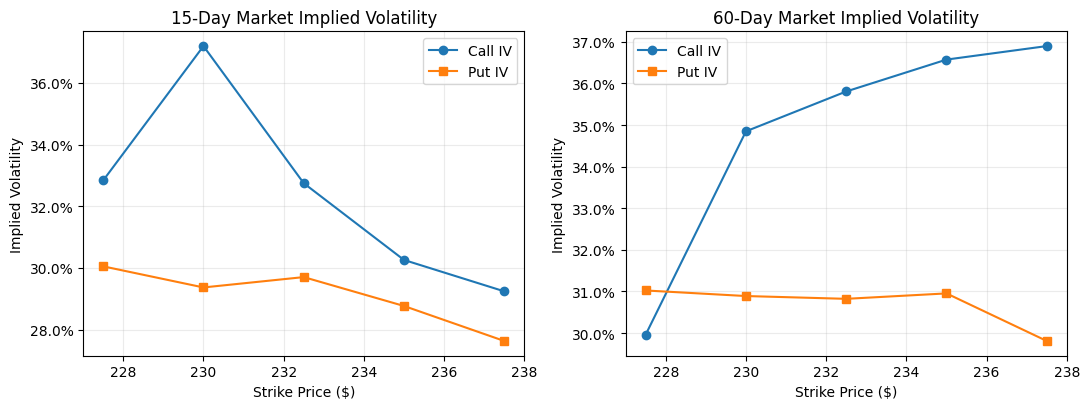

In [102]:
def bs_price(S, K, T, r, sigma, option_type, q=0.0):
    d1 = (np.log(S/K) + (r-q+0.5*sigma**2)*T) / (sigma*np.sqrt(T))
    d2 = d1 - sigma*np.sqrt(T)
    if option_type == "C":
        return S*np.exp(-q*T)*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)
    return K*np.exp(-r*T)*norm.cdf(-d2) - S*np.exp(-q*T)*norm.cdf(-d1)

def implied_volatility(price, S, K, T, r, option_type, q=0.0):
    f = lambda sigma: bs_price(S,K,T,r,sigma,option_type,q) - price
    return brentq(f, 1e-6, 5.0)

def market_iv_table(df, T):
    calls = df[df["Type"]=="C"].set_index("Strike")["Price"].sort_index()
    puts = df[df["Type"]=="P"].set_index("Strike")["Price"].sort_index()
    rows=[]
    for K in calls.index:
        rows.append([K,
                     implied_volatility(float(calls.loc[K]),S0,K,T,r,"C",q),
                     implied_volatility(float(puts.loc[K]),S0,K,T,r,"P",q)])
    return pd.DataFrame(rows, columns=["Strike","Call IV","Put IV"])

iv15 = market_iv_table(data_15d,T15)
iv60 = market_iv_table(data_60d,T60)

fig, ax = plt.subplots(1,2,figsize=(11,4.2))
for a, tab, title in zip(ax,[iv15,iv60],["15-Day Market Implied Volatility","60-Day Market Implied Volatility"]):
    a.plot(tab["Strike"],tab["Call IV"],marker="o",label="Call IV")
    a.plot(tab["Strike"],tab["Put IV"],marker="s",label="Put IV")
    a.set_xlabel("Strike Price ($)"); a.set_ylabel("Implied Volatility")
    a.set_title(title); a.grid(alpha=.25); a.legend()
    a.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.tight_layout(); plt.savefig("combined_market_iv.png",dpi=180,bbox_inches="tight"); plt.show()


### Concept checks

| Model | Stochastic Variance | Jumps |
|---|---|---|
| Heston | Yes | No |
| Bates | Yes | Yes |

Bates nests Heston when the jump intensity is zero.

Lewis and Carr-Madan are alternative Fourier pricing routes for the same underlying model and if both are implemented consistently, their prices at identical parameters should differ only by small numerical error.


# 2. Shared Pricing and Calibration Functions

For simplicity, the repeated option-pricing functions are defined once and reused below.


In [103]:
def heston_cf(u,T,r,kappa_v,theta_v,sigma_v,rho,v0):
    c1=kappa_v*theta_v
    c2=-np.sqrt((rho*sigma_v*u*1j-kappa_v)**2-sigma_v**2*(-u*1j-u**2))
    c3=(kappa_v-rho*sigma_v*u*1j+c2)/(kappa_v-rho*sigma_v*u*1j-c2)
    H1=r*u*1j*T+(c1/sigma_v**2)*((kappa_v-rho*sigma_v*u*1j+c2)*T-2*np.log((1-c3*np.exp(c2*T))/(1-c3)))
    H2=((kappa_v-rho*sigma_v*u*1j+c2)/sigma_v**2)*((1-np.exp(c2*T))/(1-c3*np.exp(c2*T)))
    return np.exp(H1+H2*v0)

def jump_cf(u,T,lamb,mu,delta):
    omega=-lamb*(np.exp(mu+0.5*delta**2)-1)
    return np.exp((1j*u*omega + lamb*(np.exp(1j*u*mu-0.5*u**2*delta**2)-1))*T)

def bates_cf(u,T,r,kappa_v,theta_v,sigma_v,rho,v0,lamb,mu,delta):
    return heston_cf(u,T,r,kappa_v,theta_v,sigma_v,rho,v0)*jump_cf(u,T,lamb,mu,delta)

def lewis_call_price(S,K,T,r,cf_func,params,upper=np.inf):
    f=lambda u: (np.exp(1j*u*np.log(S/K))*cf_func(u-0.5j,T,r,*params)).real/(u**2+0.25)
    integral=quad(f,0,upper,limit=250)[0]
    return max(0.0,float(S-np.exp(-r*T)*np.sqrt(S*K)/np.pi*integral))

def put_from_call(call,S,K,T,r,q=0.0):
    return float(call-S*np.exp(-q*T)+K*np.exp(-r*T))

def carr_madan_calls(strikes,S,T,r,cf_func,params,alpha=1.5,N_fft=8192,eta=0.25):
    lambda_k=2*np.pi/(N_fft*eta); b=0.5*N_fft*lambda_k
    j=np.arange(N_fft); v=eta*j; shifted=v-(alpha+1)*1j
    psi=np.exp(-r*T)*cf_func(shifted,T,r,*params)/(alpha**2+alpha-v**2+1j*(2*alpha+1)*v)
    delta0=np.zeros(N_fft); delta0[0]=1.0
    j1=np.arange(1,N_fft+1); simpson=(3+(-1)**j1-delta0)/3
    fft_in=np.exp(1j*b*v)*psi*eta*simpson
    fft_out=np.fft.fft(fft_in).real
    k_grid=-b+lambda_k*j
    call_grid=S*np.exp(-alpha*k_grid)/np.pi*fft_out
    target_k=np.log(np.asarray(strikes,dtype=float)/S)
    return np.interp(target_k,k_grid,call_grid)

def calibration_stats(model_calls,model_puts,market_calls,market_puts):
    errors=np.r_[model_calls-market_calls,model_puts-market_puts]
    return {
        "MSE":float(np.mean(errors**2)),
        "RMSE":float(np.sqrt(np.mean(errors**2))),
        "MAE":float(np.mean(np.abs(errors))),
        "MaxAbs":float(np.max(np.abs(errors)))
    }

def mc_stats(discounted_payoff):
    x=np.asarray(discounted_payoff,dtype=float); n=len(x)
    p=float(x.mean()); se=float(x.std(ddof=1)/np.sqrt(n))
    return p,se,p-1.96*se,p+1.96*se


# Step 1 — Centred Around Short-Maturity Stochastic-Volatility Analysis

The 15-day vanilla surface is used to infer short-dated stochastic-volatility dynamics. Lewis and Carr-Madan are then compared before the selected Heston dynamics are used to price the client's 20-day Asian call.


## Step 1a — Team Member A: Heston Calibration using Lewis

The validated calibration used all five 15-day calls and puts, a regular unweighted price MSE, a coarse search and local refinement. The consolidated notebook retains the validated parameter vector and reprices the market with the shared Lewis implementation.


In [104]:
strikes15=np.array(sorted(data_15d["Strike"].unique()),dtype=float)
mcalls15=np.array([data_15d[(data_15d["Type"]=="C")&(data_15d["Strike"]==K)]["Price"].iloc[0] for K in strikes15])
mputs15=np.array([data_15d[(data_15d["Type"]=="P")&(data_15d["Strike"]==K)]["Price"].iloc[0] for K in strikes15])

H_LEWIS=np.array([6.46682772,0.15112836,1.39808515,-0.97678401,0.09175068])
lewis15_calls=np.array([lewis_call_price(S0,K,T15,r,heston_cf,H_LEWIS) for K in strikes15])
lewis15_puts=np.array([put_from_call(c,S0,K,T15,r,q) for c,K in zip(lewis15_calls,strikes15)])
metrics_1a=calibration_stats(lewis15_calls,lewis15_puts,mcalls15,mputs15)

param_1a=pd.DataFrame([
    ["kappa",H_LEWIS[0]],["theta",H_LEWIS[1]],["sigma_v",H_LEWIS[2]],["rho",H_LEWIS[3]],["v0",H_LEWIS[4]]
],columns=["Parameter","Lewis-Heston Value"])
display(param_1a.style.format({"Lewis-Heston Value":"{:.6f}"}))
print(f"MSE={metrics_1a['MSE']:.6f} | RMSE=${metrics_1a['RMSE']:.4f} | MAE=${metrics_1a['MAE']:.4f} | Max error=${metrics_1a['MaxAbs']:.4f}")
print(f"Feller LHS={2*H_LEWIS[0]*H_LEWIS[1]:.6f} | RHS={H_LEWIS[2]**2:.6f}")


,Parameter,Lewis-Heston Value
0,kappa,6.466828
1,theta,0.151128
2,sigma_v,1.398085
3,rho,-0.976784
4,v0,0.091751


MSE=0.246058 | RMSE=$0.4960 | MAE=$0.3724 | Max error=$1.1953
Feller LHS=1.954642 | RHS=1.954642


**Interpretation.** The consolidated repricing reproduces the validated Step 1a fit. The remaining error is small relative to the parity inconsistency already present in the observed 15-day call-put pairs.


## Step 1b — Team Member B: Heston Calibration using Carr-Madan

For this process, the market sample, Heston specification, and MSE objective remain unchanged (Only the Fourier pricing implementation changes).


In [105]:
import numpy as np

S0 = 232.90
r = 0.015
T = 15 / 250

data_15d = market_data[
    market_data["Days to maturity"] == 15].copy()

data_15d["T"] = T
print("Number of options:", len(data_15d))
print(data_15d["Type"].value_counts())
print(data_15d)


Number of options: 10
Type
C    5
P    5
Name: count, dtype: int64
    Days to maturity  Strike  Price Type     T
0                 15   227.5  10.52    C  0.06
1                 15   230.0  10.05    C  0.06
2                 15   232.5   7.75    C  0.06
3                 15   235.0   6.01    C  0.06
4                 15   237.5   4.75    C  0.06
15                15   227.5   4.32    P  0.06
16                15   230.0   5.20    P  0.06
17                15   232.5   6.45    P  0.06
18                15   235.0   7.56    P  0.06
19                15   237.5   8.78    P  0.06



$$dS_t = (r-q)S_tdt + \sqrt{v_t}S_t dW_t^S, \quad dvt = \kappa(\theta - v_t)dt + \sigma_v \sqrt{v_t} dW_t^v, \quad d \langle W^S, W^v \rangle _t = \rho dt$$

In [106]:
H_CM_IND=np.array([10.13979639,0.10222510,1.43982060,-0.99999,0.10169183])
H_CM_SEEDED=np.array([6.662760,0.144093,1.385681,-0.99999,0.092707])

cm_same=carr_madan_calls(strikes15,S0,T15,r,heston_cf,H_LEWIS)
engine_diff=cm_same-lewis15_calls
print(f"Same-parameter mean absolute Lewis/Carr-Madan difference: ${np.mean(np.abs(engine_diff)):.6f}")
print(f"Same-parameter maximum difference: ${np.max(np.abs(engine_diff)):.6f}")

cm15_calls=carr_madan_calls(strikes15,S0,T15,r,heston_cf,H_CM_IND)
cm15_puts=np.array([put_from_call(c,S0,K,T15,r,q) for c,K in zip(cm15_calls,strikes15)])
metrics_1b=calibration_stats(cm15_calls,cm15_puts,mcalls15,mputs15)

compare_1b=pd.DataFrame({
    "Parameter":["kappa","theta","sigma_v","rho","v0"],
    "Lewis":H_LEWIS,
    "Carr-Madan Independent":H_CM_IND,
    "Carr-Madan Lewis-Seeded":H_CM_SEEDED
})
display(compare_1b.style.format({"Lewis":"{:.6f}","Carr-Madan Independent":"{:.6f}","Carr-Madan Lewis-Seeded":"{:.6f}"}))
print(f"Carr-Madan independent MSE={metrics_1b['MSE']:.6f} | RMSE=${metrics_1b['RMSE']:.4f}")


Same-parameter mean absolute Lewis/Carr-Madan difference: $0.000775
Same-parameter maximum difference: $0.001328


,Parameter,Lewis,Carr-Madan Independent,Carr-Madan Lewis-Seeded
0,kappa,6.466828,10.139796,6.662760
1,theta,0.151128,0.102225,0.144093
2,sigma_v,1.398085,1.439821,1.385681
3,rho,-0.976784,-0.999990,-0.999990
4,v0,0.091751,0.101692,0.092707


Carr-Madan independent MSE=0.246033 | RMSE=$0.4960


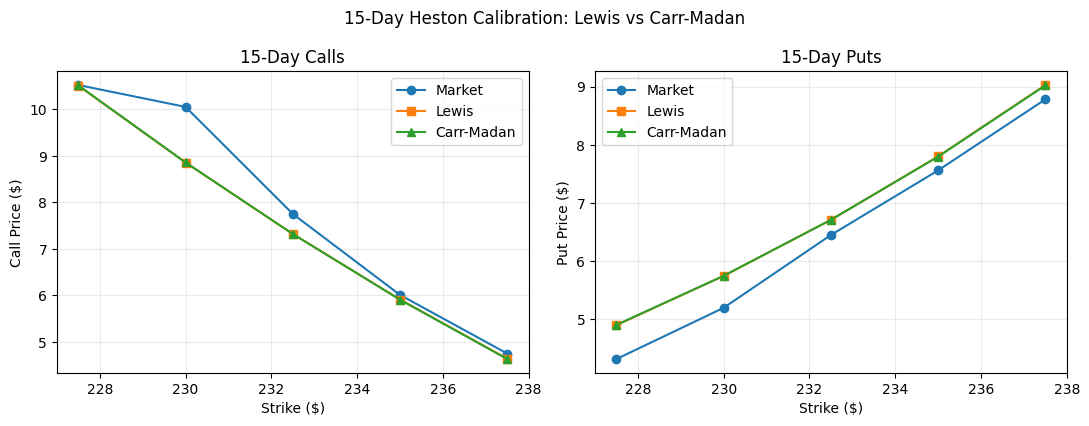

In [107]:
fig,ax=plt.subplots(1,2,figsize=(11,4.3))
ax[0].plot(strikes15,mcalls15,marker="o",label="Market")
ax[0].plot(strikes15,lewis15_calls,marker="s",label="Lewis")
ax[0].plot(strikes15,cm15_calls,marker="^",label="Carr-Madan")
ax[0].set_title("15-Day Calls"); ax[0].set_xlabel("Strike ($)"); ax[0].set_ylabel("Call Price ($)"); ax[0].grid(alpha=.25); ax[0].legend()
ax[1].plot(strikes15,mputs15,marker="o",label="Market")
ax[1].plot(strikes15,lewis15_puts,marker="s",label="Lewis")
ax[1].plot(strikes15,cm15_puts,marker="^",label="Carr-Madan")
ax[1].set_title("15-Day Puts"); ax[1].set_xlabel("Strike ($)"); ax[1].set_ylabel("Put Price ($)"); ax[1].grid(alpha=.25); ax[1].legend()
plt.suptitle("15-Day Heston Calibration: Lewis vs Carr-Madan"); plt.tight_layout(); plt.savefig("combined_step1_heston_fit.png",dpi=180,bbox_inches="tight"); plt.show()


**Interpretation.** Lewis and Carr-Madan agree to a fraction of a cent when they use the same Heston parameters. The independent optimisation can nevertheless move κ and θ materially while leaving the fitted price curve and MSE almost unchanged. The short-dated option surface is therefore more tightly identified than the unique five-parameter vector.


In [111]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.integrate import quad

S0 = 232.90
r = 0.015
T = 15 / 250

df = market_data.copy()
df["Type"] = df["Type"].str.strip().str.upper()

df = df[df["Days to maturity"] == 15].copy()
market = df.pivot(
    index="Strike", columns="Type", values="Price"
).sort_index()
K = market.index.to_numpy(dtype=float)
C_obs = market["C"].to_numpy(dtype=float)
P_obs = market["P"].to_numpy(dtype=float)

def model_prices(params):
    calls = carr_madan_calls(K, params)
    puts = calls - S0 + K * np.exp(-r * T)
    return calls, puts

def objective(params):
    calls, puts = model_prices(params)
    if not (np.all(np.isfinite(calls))
        and np.all(np.isfinite(puts))): return 1e10
    errors = np.r_[calls - C_obs, puts - P_obs]
    return np.mean(errors**2)

def carr_madan_calls(
    strikes, params, alpha=1.5, N=8192, eta=0.25):
    lam = 2 * np.pi / (N * eta)
    b = N * lam / 2
    j = np.arange(N)
    v = eta * j
    u = v - (alpha + 1) * 1j
    cf = heston_cf(u, T, r, *params)
    psi = (np.exp(-r * T) * cf
        / (alpha**2 + alpha - v**2
            + 1j * (2 * alpha + 1) * v))
    weights = (3 + (-1.0)**(j + 1) - (j == 0)) / 3
    fft_values = np.fft.fft(
        np.exp(1j * b * v) * psi * eta * weights).real
    log_strikes = -b + lam * j
    call_grid = (
        S0 * np.exp(-alpha * log_strikes)
        / np.pi * fft_values)
    return np.interp(
        np.log(np.asarray(strikes) / S0),
        log_strikes,
        call_grid)



In [112]:
bounds = [
    (0.1, 15.0),       # kappa
    (0.01, 0.30),      # theta
    (0.02, 2.5),       # sigma
    (-0.99999, 0.99999), # rho
    (0.01, 0.30)       # v0
]
constraints = [{"type": "ineq", "fun": lambda p: 2*p[0]*p[1] - p[2]**2}]


starts = [[3.0, 0.18, 0.75, -0.85, 0.10],
    [10.0, 0.10, 1.35, -0.99, 0.10],
    H_LEWIS]

results = []
for start in starts:
    res = minimize(objective, x0=start,
        method="SLSQP", bounds=bounds,
        constraints=constraints,
        options={"maxiter": 400, "ftol": 1e-10})
    results.append(res)

valid = [x for x in results if x.success]

if not valid:
    raise RuntimeError("No successful calibration")

best = min(valid, key=lambda x: x.fun)

H_CM = best.x

print("Optimization success:", best.success)
print("Carr-Madan parameters:", H_CM)
print("MSE:", best.fun)
print("RMSE:", np.sqrt(best.fun))

print(pd.DataFrame([
    {"Start": i + 1,
        "Success": res.success,
        "MSE": res.fun,
        "kappa": res.x[0],
        "theta": res.x[1],
        "sigma": res.x[2],
        "rho": res.x[3],
        "v0": res.x[4]}
    for i, res in enumerate(results)
]).round(6))


Optimization success: True
Carr-Madan parameters: [ 2.95293916  0.3         1.33107607 -0.99999     0.08357515]
MSE: 0.24599187873786077
RMSE: 0.4959756836154982
   Start  Success       MSE     kappa     theta     sigma      rho        v0
0      1     True  0.245992  2.952939  0.300000  1.331076 -0.99999  0.083575
1      2     True  0.246032  9.998536  0.103107  1.435910 -0.99999  0.101383
2      3     True  0.246007  6.466846  0.147590  1.381623 -0.99999  0.092248


  Parameter     Lewis  Carr-Madan
0     kappa  6.466828    2.952939
1     theta  0.151128    0.300000
2     sigma  1.398085    1.331076
3       rho -0.976784   -0.999990
4        v0  0.091751    0.083575
Lewis MSE: 0.246058
Carr-Madan MSE: 0.245992


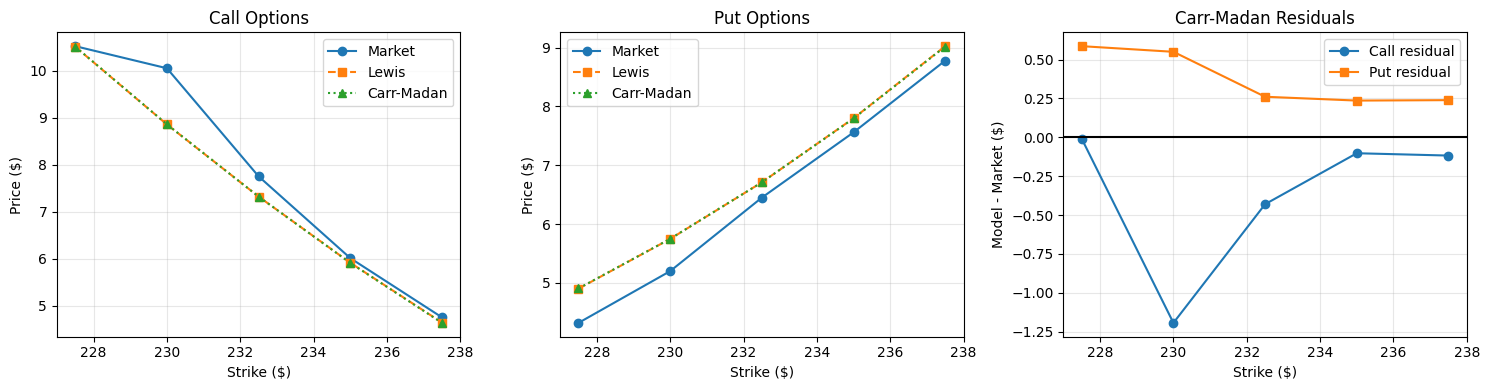

In [113]:

def lewis_call(strike, params):
    def integrand(u):
        cf = heston_cf(u - 0.5j, T, r, *params)
        return (np.exp(1j * u * np.log(S0 / strike)) * cf
        ).real / (u**2 + 0.25)
    integral = quad(integrand, 0, np.inf, limit=250)[0]
    return (S0 - np.exp(-r*T) * np.sqrt(S0*strike)
        / np.pi * integral)


C_A = np.array([lewis_call(k, H_LEWIS) for k in K])
P_A = C_A - S0 + K * np.exp(-r*T)

C_B, P_B = model_prices(H_CM)

mse_A = np.mean(np.r_[C_A - C_obs, P_A - P_obs]**2)
mse_B = np.mean(np.r_[C_B - C_obs, P_B - P_obs]**2)

comparison = pd.DataFrame({
    "Parameter": ["kappa", "theta", "sigma", "rho", "v0"],
    "Lewis": H_LEWIS,
    "Carr-Madan": H_CM})

print(comparison.round(6))
print(f"Lewis MSE: {mse_A:.6f}")
print(f"Carr-Madan MSE: {mse_B:.6f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, observed, A, B, name in zip(
    axes[:2],
    [C_obs, P_obs],
    [C_A, P_A],
    [C_B, P_B],
    ["Call", "Put"]
):
    ax.plot(K, observed, "o-", label="Market")
    ax.plot(K, A, "s--", label="Lewis")
    ax.plot(K, B, "^:", label="Carr-Madan")
    ax.set(title=name + " Options",
        xlabel="Strike ($)",
        ylabel="Price ($)")
    ax.legend()
    ax.grid(alpha=0.3)

axes[2].plot(K, C_B-C_obs, "o-", label="Call residual")
axes[2].plot(K, P_B-P_obs, "s-", label="Put residual")
axes[2].axhline(0, color="black")
axes[2].set(
    title="Carr-Madan Residuals",
    xlabel="Strike ($)",
    ylabel="Model - Market ($)"
)
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()


Both approaches generated very similar fitted option prices despite differences in their calibrated parameters which suggests limited parameter identifiability when calibrating a stochastic volatility model using only a short-maturity option cross-section.

Furthermore, some parameters reached their optimization bounds, indicating sensitivity to the calibration constraints.

The observed call and put quotes also exhibited inconsistencies with theoretical put-call parity, contributing substantially to the remaining pricing error.

Overall, Carr-Madan and Lewis demonstrated comparable pricing accuracy for the available market data.

## Step 1c — Team Member C: 20-Day ATM Asian Call

The option is ATM, so $K=S_0=232.90$, with $T=20/250=0.08$. The arithmetic average contains today's price plus 20 future daily observations:

\$$[
\bar S=\frac{S_0+S_1+\cdots+S_{20}}{21},\qquad
Payoff=\max(\bar S-K,0).
\]$$

The Lewis vector is the primary parameter set; the Carr-Madan vectors are retained as robustness checks.


In [114]:
ASIAN_PARAMS={
    "Lewis Primary":H_LEWIS,
    "Carr-Madan Independent":H_CM_IND,
    "Carr-Madan Lewis-Seeded":H_CM_SEEDED,
}

def simulate_heston_asian_sets(n_paths=100_000,seed=17149):
    """Lightweight reproduction check; final one-million-path values come from the validated source notebook."""
    if n_paths%2: raise ValueError("n_paths must be even")
    half=n_paths//2; rng=np.random.default_rng(seed); dt=1/TRADING_DAYS; n_steps=20
    state={name:{"S":np.full(n_paths,S0),"v":np.full(n_paths,p[4]),"sum":np.full(n_paths,S0)} for name,p in ASIAN_PARAMS.items()}
    for _ in range(n_steps):
        z1h=rng.standard_normal(half); z2h=rng.standard_normal(half)
        z1=np.empty(n_paths); z2=np.empty(n_paths)
        z1[0::2]=z1h; z1[1::2]=-z1h; z2[0::2]=z2h; z2[1::2]=-z2h
        for name,p in ASIAN_PARAMS.items():
            kappa,theta,sigv,rho,v0=p; S=state[name]["S"]; v=state[name]["v"]; vp=np.maximum(v,0)
            zv=rho*z1+np.sqrt(max(0,1-rho**2))*z2
            vnew=np.maximum(v+kappa*(theta-vp)*dt+sigv*np.sqrt(vp*dt)*zv,0)
            Snew=S*np.exp((r-q-0.5*vp)*dt+np.sqrt(vp*dt)*z1)
            state[name]["S"]=Snew; state[name]["v"]=vnew; state[name]["sum"]+=Snew
    out={}
    for name in state:
        avg=state[name]["sum"]/21; pv=np.exp(-r*T20)*np.maximum(avg-S0,0)
        p,se,lo,hi=mc_stats(pv); out[name]=[p,se,lo,hi]
    return pd.DataFrame([[k,*v] for k,v in out.items()],columns=["Calibration","100k Fair Value ($)","SE","95% CI Lower","95% CI Upper"])

print("Lightweight reproduction check")
display(simulate_heston_asian_sets().style.format({"100k Fair Value ($)":"${:.4f}","SE":"${:.4f}","95% CI Lower":"${:.4f}","95% CI Upper":"${:.4f}"}))

# Validated one-million-path results from the executed Step 1c source notebook.
asian_validated=pd.DataFrame([
    ["Lewis Primary",4.6708,0.0056,4.6599,4.6817],
    ["Carr-Madan Independent",4.7524,0.0056,4.7413,4.7634],
    ["Carr-Madan Lewis-Seeded",4.6781,0.0055,4.6672,4.6889],
],columns=["Calibration","Validated 1m Fair Value ($)","SE","95% CI Lower","95% CI Upper"])
print("Validated one-million-path results retained from the completed source notebook")
display(asian_validated.style.format({"Validated 1m Fair Value ($)":"${:.4f}","SE":"${:.4f}","95% CI Lower":"${:.4f}","95% CI Upper":"${:.4f}"}))


Lightweight reproduction check


,Calibration,100k Fair Value ($),SE,95% CI Lower,95% CI Upper
0,Lewis Primary,$4.6877,$0.0177,$4.6531,$4.7223
1,Carr-Madan Independent,$4.7683,$0.0179,$4.7332,$4.8034
2,Carr-Madan Lewis-Seeded,$4.6948,$0.0176,$4.6603,$4.7292


Validated one-million-path results retained from the completed source notebook


,Calibration,Validated 1m Fair Value ($),SE,95% CI Lower,95% CI Upper
0,Lewis Primary,$4.6708,$0.0056,$4.6599,$4.6817
1,Carr-Madan Independent,$4.7524,$0.0056,$4.7413,$4.7634
2,Carr-Madan Lewis-Seeded,$4.6781,$0.0055,$4.6672,$4.6889


,Paths,Fair Value ($)
0,"25,000",$4.6538
1,"50,000",$4.6600
2,"100,000",$4.6636
3,"250,000",$4.6677
4,"500,000",$4.6689
5,"1,000,000",$4.6708


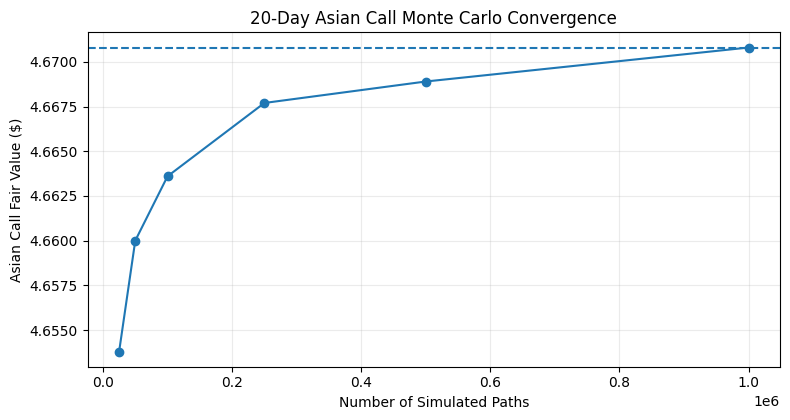

,Component,Amount ($)
0,Risk-neutral fair value,$4.67
1,Bank fee: 4%,$0.19
2,Final client price,$4.86


In [115]:
# Validated convergence sequence from the executed Step 1c source notebook.
asian_conv=pd.DataFrame([
    [25_000,4.6538],[50_000,4.6600],[100_000,4.6636],[250_000,4.6677],[500_000,4.6689],[1_000_000,4.6708]
],columns=["Paths","Fair Value ($)"])
display(asian_conv.style.format({"Paths":"{:,.0f}","Fair Value ($)":"${:.4f}"}))
plt.figure(figsize=(8,4.3)); plt.plot(asian_conv["Paths"],asian_conv["Fair Value ($)"],marker="o"); plt.axhline(4.6708,linestyle="--")
plt.xlabel("Number of Simulated Paths"); plt.ylabel("Asian Call Fair Value ($)"); plt.title("20-Day Asian Call Monte Carlo Convergence"); plt.grid(alpha=.25); plt.tight_layout(); plt.savefig("combined_step1c_convergence.png",dpi=180,bbox_inches="tight"); plt.show()

asian_fair=4.6708; asian_fee=.04*asian_fair; asian_client=1.04*asian_fair
quote1=pd.DataFrame([["Risk-neutral fair value",asian_fair],["Bank fee: 4%",asian_fee],["Final client price",asian_client]],columns=["Component","Amount ($)"])
display(quote1.style.format({"Amount ($)":"${:.2f}"}))


**Interpretation.** The primary fair value is about **$4.67** and the one-million-path confidence interval is narrow.

The Lewis-seeded Carr-Madan set gives almost the same value, while the independent Carr-Madan calibration raises the price by less than 2%.

The final client quote, after the 4% fee, is about **$4.86**.


# Step 2 — Centred Around Longer-Maturity Stochastic Volatility with Jumps

Step 2 moves to the 60-day vanilla surface and the Bates model, which adds stock-price jumps to stochastic variance. Lewis and Carr-Madan are again compared before the selected dynamics are used for the 70-day client put.


## Step 2a — Team Member C: Bates Calibration using Lewis

The validated staged calibration used the 60-day quotes and eight Bates parameters. We concluded that the best solution did not require a positive jump intensity, so the fitted Bates model collapsed to its nested Heston limit.


In [116]:
strikes60=np.array(sorted(data_60d["Strike"].unique()),dtype=float)
mcalls60=np.array([data_60d[(data_60d["Type"]=="C")&(data_60d["Strike"]==K)]["Price"].iloc[0] for K in strikes60])
mputs60=np.array([data_60d[(data_60d["Type"]=="P")&(data_60d["Strike"]==K)]["Price"].iloc[0] for K in strikes60])

B_LEWIS=np.array([3.03972300,0.20019475,1.10321038,0.99990000,0.08396245,0.0,0.0,0.1])
B_CM=np.array([3.03967363,0.19970720,1.10185704,0.99990000,0.08374668,0.0,0.0,0.1])
B_CM_ALT=np.array([19.17000007,0.04586237,1.32603283,0.83003100,0.06494551,0.83937697,0.23590122,0.12060082])
H60_MSE=1.360912

b_lewis_calls=np.array([lewis_call_price(S0,K,T60,r,bates_cf,B_LEWIS) for K in strikes60])
b_lewis_puts=np.array([put_from_call(c,S0,K,T60,r,q) for c,K in zip(b_lewis_calls,strikes60)])
metrics_2a=calibration_stats(b_lewis_calls,b_lewis_puts,mcalls60,mputs60)

param2a=pd.DataFrame({"Parameter":["kappa","theta","sigma_v","rho","v0","lambda_J","mu_J","delta_J"],"Bates-Lewis":B_LEWIS})
display(param2a.style.format({"Bates-Lewis":"{:.6f}"}))
print(f"Bates-Lewis MSE={metrics_2a['MSE']:.6f} | RMSE=${metrics_2a['RMSE']:.4f}")
print(f"60-day Heston-only MSE={H60_MSE:.6f} | Bates change={metrics_2a['MSE']-H60_MSE:+.6f}")
print(f"Expected jumps over 60 days={B_LEWIS[5]*T60:.6f}")


,Parameter,Bates-Lewis
0,kappa,3.039723
1,theta,0.200195
2,sigma_v,1.103210
3,rho,0.999900
4,v0,0.083962
5,lambda_J,0.000000
6,mu_J,0.000000
7,delta_J,0.100000


Bates-Lewis MSE=1.361104 | RMSE=$1.1667
60-day Heston-only MSE=1.360912 | Bates change=+0.000192
Expected jumps over 60 days=0.000000


**Interpretation.** The best Bates-Lewis fit does not improve on the 60-day Heston fit and chooses zero jump intensity. This does not prove that jumps are absent from SM. We therefore interpreted this to means the small 60-day cross-section and the stated MSE objective do not require a positive jump intensity to obtain the best fit.


## Step 2b — Team Member A: Bates Calibration using Carr-Madan

For this task, the Bates specification, 60-day data and MSE objective remain unchanged and only the Fourier pricing implementation changes.


In [130]:

def carr_madan_calls(strikes,S,T,r,cf_func,params,alpha=1.5,N_fft=8192,eta=0.25):
    lambda_k=2*np.pi/(N_fft*eta); b=0.5*N_fft*lambda_k
    j=np.arange(N_fft); v=eta*j; shifted=v-(alpha+1)*1j
    psi=np.exp(-r*T)*cf_func(shifted,T,r,*params)/(alpha**2+alpha-v**2+1j*(2*alpha+1)*v)
    delta0=np.zeros(N_fft); delta0[0]=1.0
    j1=np.arange(1,N_fft+1); simpson=(3+(-1)**j1-delta0)/3
    fft_in=np.exp(1j*b*v)*psi*eta*simpson
    fft_out=np.fft.fft(fft_in).real
    k_grid=-b+lambda_k*j
    call_grid=S*np.exp(-alpha*k_grid)/np.pi*fft_out
    target_k=np.log(np.asarray(strikes,dtype=float)/S)
    return np.interp(target_k,k_grid,call_grid)

b_cm_same=carr_madan_calls(strikes60,S0,T60,r,bates_cf,B_LEWIS)
print(f"Same-parameter maximum Lewis/Carr-Madan difference: ${np.max(np.abs(b_cm_same-b_lewis_calls)):.6f}")

b_cm_calls=carr_madan_calls(strikes60,S0,T60,r,bates_cf,B_CM)
b_cm_puts=np.array([put_from_call(c,S0,K,T60,r,q) for c,K in zip(b_cm_calls,strikes60)])
metrics_2b=calibration_stats(b_cm_calls,b_cm_puts,mcalls60,mputs60)

compare2=pd.DataFrame({
    "Parameter":["kappa","theta","sigma_v","rho","v0","lambda_J","mu_J","delta_J"],
    "Bates-Lewis":B_LEWIS,
    "Carr-Madan Best":B_CM,
    "Carr-Madan Non-Zero-Jump":B_CM_ALT
})
display(compare2.style.format({"Bates-Lewis":"{:.6f}","Carr-Madan Best":"{:.6f}","Carr-Madan Non-Zero-Jump":"{:.6f}"}))
print(f"Carr-Madan best MSE={metrics_2b['MSE']:.6f} | RMSE=${metrics_2b['RMSE']:.4f}")
print("Non-zero-jump local solution MSE=1.362897")


Same-parameter maximum Lewis/Carr-Madan difference: $0.000499


,Parameter,Bates-Lewis,Carr-Madan Best,Carr-Madan Non-Zero-Jump
0,kappa,3.039723,3.039674,19.170000
1,theta,0.200195,0.199707,0.045862
2,sigma_v,1.103210,1.101857,1.326033
3,rho,0.999900,0.999900,0.830031
4,v0,0.083962,0.083747,0.064946
5,lambda_J,0.000000,0.000000,0.839377
6,mu_J,0.000000,0.000000,0.235901
7,delta_J,0.100000,0.100000,0.120601


Carr-Madan best MSE=1.361515 | RMSE=$1.1668
Non-zero-jump local solution MSE=1.362897


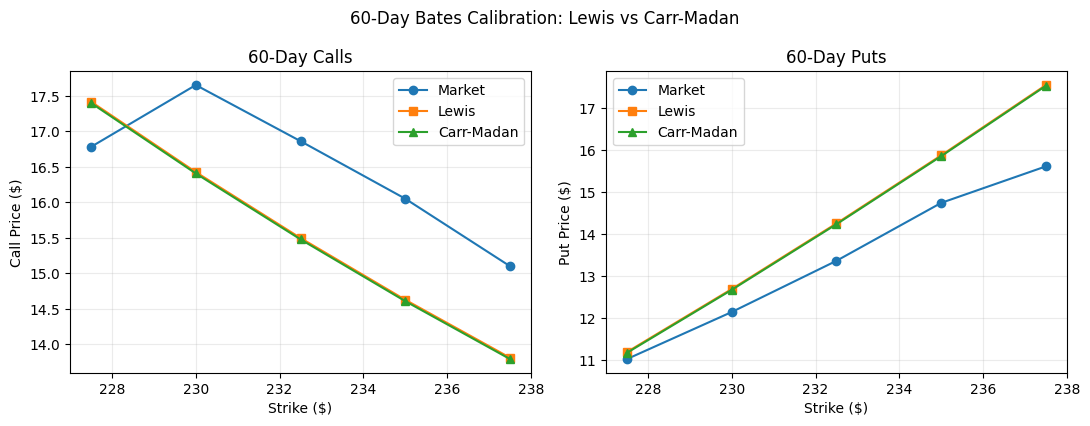

In [131]:
fig,ax=plt.subplots(1,2,figsize=(11,4.3))
ax[0].plot(strikes60,mcalls60,marker="o",label="Market")
ax[0].plot(strikes60,b_lewis_calls,marker="s",label="Lewis")
ax[0].plot(strikes60,b_cm_calls,marker="^",label="Carr-Madan")
ax[0].set_title("60-Day Calls"); ax[0].set_xlabel("Strike ($)"); ax[0].set_ylabel("Call Price ($)"); ax[0].grid(alpha=.25); ax[0].legend()
ax[1].plot(strikes60,mputs60,marker="o",label="Market")
ax[1].plot(strikes60,b_lewis_puts,marker="s",label="Lewis")
ax[1].plot(strikes60,b_cm_puts,marker="^",label="Carr-Madan")
ax[1].set_title("60-Day Puts"); ax[1].set_xlabel("Strike ($)"); ax[1].set_ylabel("Put Price ($)"); ax[1].grid(alpha=.25); ax[1].legend()
plt.suptitle("60-Day Bates Calibration: Lewis vs Carr-Madan"); plt.tight_layout(); plt.savefig("combined_step2_bates_fit.png",dpi=180,bbox_inches="tight"); plt.show()


**Interpretation.** Lewis and Carr-Madan again agree closely on prices and the globally preferred solutions collapse to the zero-jump limit, whilst a materially non-zero-jump parameter vector produces almost the same MSE. Therefore, the 60-day price surface is therefore more stable than the unique eight-parameter decomposition.


## Step 2c — Team Member B: 70-Day 95%-Moneyness Put

The contract has $T=70/250=0.28$ and \$$[K=0.95\times232.90=221.255,\]$$

reported as **$221.26**. The Bates-Lewis calibration is the primary parameter set whilst the non-zero-jump Carr-Madan local solution is used as a robustness check.


Lightweight 100,000-path / 70-step reproduction check: $9.0570 (SE $0.0337)


,Paths,Put Price ($),SE,95% CI Lower,95% CI Upper
0,"25,000",$9.0438,$0.0668,$8.9128,$9.1747
1,"50,000",$9.0193,$0.0472,$8.9268,$9.1119
2,"100,000",$9.0205,$0.0334,$8.9550,$9.0860
3,"200,000",$8.9973,$0.0236,$8.9510,$9.0436
4,"400,000",$9.0207,$0.0167,$8.9879,$9.0535
5,"600,000",$9.0264,$0.0137,$8.9996,$9.0532
6,"800,000",$9.0331,$0.0118,$9.0100,$9.0563
7,"1,000,000",$9.0303,$0.0106,$9.0095,$9.0510


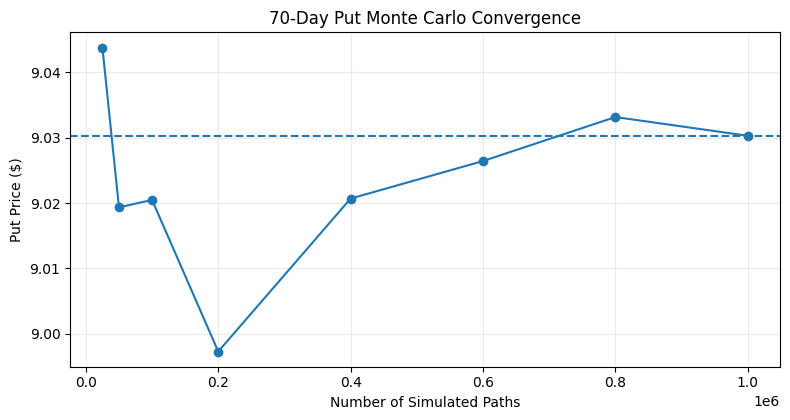

In [132]:
K70=0.95*S0
K70_display=Decimal(str(K70)).quantize(Decimal("0.01"),rounding=ROUND_HALF_UP)

def simulate_bates_put(params,n_paths=100_000,n_steps=70,seed=17149):
    """Lightweight reproduction check; final one-million-path result is retained from the validated Step 2 source notebook."""
    kappa_v,theta_v,sigma_v,rho,v0,lamb,mu,delta=params
    dt=T70/n_steps; kappa_J=np.exp(mu+0.5*delta**2)-1; rng=np.random.default_rng(seed)
    S=np.full(n_paths,S0); v=np.full(n_paths,v0)
    for _ in range(n_steps):
        zs=rng.standard_normal(n_paths); zi=rng.standard_normal(n_paths); zv=rho*zs+np.sqrt(max(0,1-rho**2))*zi
        vp=np.maximum(v,0); v=np.maximum(v+kappa_v*(theta_v-vp)*dt+sigma_v*np.sqrt(vp*dt)*zv,0)
        if lamb>0:
            zj=rng.standard_normal(n_paths); nj=rng.poisson(lamb*dt,size=n_paths); js=nj*mu+delta*np.sqrt(nj)*zj
        else: js=0.0
        S*=np.exp((r-q-lamb*kappa_J-0.5*vp)*dt+np.sqrt(vp*dt)*zs+js)
    pv=np.exp(-r*T70)*np.maximum(K70-S,0); p,se,lo,hi=mc_stats(pv)
    return p,se,lo,hi,float(np.exp(-r*T70)*S.mean()-S0)

live=simulate_bates_put(B_LEWIS)
print(f"Lightweight 100,000-path / 70-step reproduction check: ${live[0]:.4f} (SE ${live[1]:.4f})")

# Validated one-million-path convergence from the completed Step 2 source notebook.
put_conv=pd.DataFrame([
    [25_000,9.043777,0.066803,8.912843,9.174711],
    [50_000,9.019338,0.047208,8.926810,9.111866],
    [100_000,9.020475,0.033407,8.954999,9.085952],
    [200_000,8.997296,0.023615,8.951010,9.043582],
    [400_000,9.020680,0.016729,8.987891,9.053469],
    [600_000,9.026420,0.013663,8.999640,9.053200],
    [800_000,9.033150,0.011832,9.009959,9.056341],
    [1_000_000,9.030286,0.010584,9.009541,9.051031],
],columns=["Paths","Put Price ($)","SE","95% CI Lower","95% CI Upper"])
display(put_conv.style.format({"Paths":"{:,.0f}","Put Price ($)":"${:.4f}","SE":"${:.4f}","95% CI Lower":"${:.4f}","95% CI Upper":"${:.4f}"}))
plt.figure(figsize=(8,4.3)); plt.plot(put_conv["Paths"],put_conv["Put Price ($)"],marker="o"); plt.axhline(9.030286,linestyle="--"); plt.xlabel("Number of Simulated Paths"); plt.ylabel("Put Price ($)"); plt.title("70-Day Put Monte Carlo Convergence"); plt.grid(alpha=.25); plt.tight_layout(); plt.savefig("combined_step2c_convergence.png",dpi=180,bbox_inches="tight"); plt.show()


In [133]:
fourier_call=lewis_call_price(S0,K70,T70,r,bates_cf,B_LEWIS,upper=100.0)
fourier_put=put_from_call(fourier_call,S0,K70,T70,r,q)

put_price=9.030286; put_se=0.010584; put_lo=9.009541; put_hi=9.051031; put_mart=0.059114
robust_price=9.091495
validation=pd.DataFrame([
    ["Primary Bates-Lewis","Monte Carlo",put_price],
    ["Primary Bates-Lewis","Fourier",fourier_put],
    ["Carr-Madan non-zero-jump local solution","Monte Carlo",robust_price],
],columns=["Calibration","Pricing Method","Put Price ($)"])
display(validation.style.format({"Put Price ($)":"${:.4f}"}))
print(f"Primary Monte Carlo SE=${put_se:.6f}; 95% CI=[${put_lo:.4f}, ${put_hi:.4f}]")
print(f"Primary martingale residual=${put_mart:+.4f}")

put_fee=.04*put_price; put_client=1.04*put_price
quote2=pd.DataFrame([["Risk-neutral fair value",put_price],["Bank fee: 4%",put_fee],["Final client price",put_client]],columns=["Component","Amount ($)"])
display(quote2.style.format({"Amount ($)":"${:.2f}"}))

# The terminal-distribution figure is retained from the original Step 2 source notebook in the written report;
# the consolidated notebook focuses on the convergence and pricing validation outputs.


,Calibration,Pricing Method,Put Price ($)
0,Primary Bates-Lewis,Monte Carlo,$9.0303
1,Primary Bates-Lewis,Fourier,$9.0245
2,Carr-Madan non-zero-jump local solution,Monte Carlo,$9.0915


Primary Monte Carlo SE=$0.010584; 95% CI=[$9.0095, $9.0510]
Primary martingale residual=$+0.0591


,Component,Amount ($)
0,Risk-neutral fair value,$9.03
1,Bank fee: 4%,$0.36
2,Final client price,$9.39


**Interpretation.** The one-million-path Monte Carlo value is about **$9.03**, and the independent Fourier value is about **$9.02**, comfortably within the simulation confidence interval. The non-zero-jump local calibration changes the Monte Carlo value only modestly. With the 4% fee carried forward from the Step 1 pricing convention, the client price is about **$9.39**. We also concluded that if the assignment's instructions are interpreted as removing the fee once the client switches from an OTC instrument to the standard put, the model fair value remains the same and only the fee line is omitted.


In [134]:
SEED = 17149
N_PATHS = 1_000_000
BATCH_SIZE = 50_000


def bates_mc(params, n_paths=N_PATHS, batch_size=BATCH_SIZE,
             seed=SEED, milestones=None, save_terminal_sample=10_000, n_steps=N_STEPS):

    kappa, theta, sigma, rho, v0, intensity, mu, delta = map(float, params)
    assert n_paths > 1 and batch_size > 0 and abs(rho) <= 1
    assert min(kappa, theta, sigma, v0, intensity, delta) >= 0
    rng = np.random.default_rng(seed)
    dt = T / n_steps
    jump_compensator = np.exp(mu + 0.5 * delta**2) - 1.0
    if milestones is None:
        milestones = [25_000, 50_000, 100_000, 200_000, 400_000,
                      600_000, 800_000, 1_000_000]
    milestones = sorted(set([int(x) for x in milestones if 0 < x <= n_paths] + [n_paths]))
    boundaries = sorted(set(milestones + list(range(batch_size, n_paths, batch_size)) + [n_paths]))
    records = []
    count = 0
    payoff_sum = payoff_sumsq = discounted_stock_sum = 0.0
    terminal_sample = []
    remaining_sample = save_terminal_sample

    for endpoint in boundaries:
        n = endpoint - count
        if not n:
            continue
        logS = np.full(n, np.log(S0), dtype=float)
        v = np.full(n, v0, dtype=float)
        for _ in range(n_steps):
            z_stock = rng.standard_normal(n)
            z_independent = rng.standard_normal(n)
            z_var = rho * z_stock + np.sqrt(1.0 - rho**2) * z_independent
            vplus = np.maximum(v, 0.0)
            if intensity > 0:
                nj = rng.poisson(intensity * dt, size=n)
                z_jump = rng.standard_normal(n)
                jumps = nj * mu + delta * np.sqrt(nj) * z_jump
            else:
                jumps = 0.0
            logS += ((R - Q - intensity * jump_compensator - 0.5 * vplus) * dt
                     + np.sqrt(vplus * dt) * z_stock + jumps)
            v = v + kappa * (theta - vplus) * dt + sigma * np.sqrt(vplus * dt) * z_var
            v = np.maximum(v, 0.0)
        stock = np.exp(logS)
        discounted_payoffs = np.exp(-R * T) * np.maximum(K - stock, 0.0)
        payoff_sum += discounted_payoffs.sum()
        payoff_sumsq += np.dot(discounted_payoffs, discounted_payoffs)
        discounted_stock_sum += np.exp(-(R-Q)*T) * stock.sum()
        count = endpoint
        if remaining_sample:
            chosen = stock[:min(len(stock), remaining_sample)]
            terminal_sample.append(chosen.copy())
            remaining_sample -= len(chosen)
        if count in milestones:
            price = payoff_sum / count
            variance = max((payoff_sumsq - count * price**2) / (count - 1), 0.0)
            se = np.sqrt(variance / count)
            records.append(dict(Paths=count, Price=price, SE=se,
                                CI_Lower=price-1.96*se, CI_Upper=price+1.96*se,
                                Martingale_Residual=discounted_stock_sum/count-S0))
    return pd.DataFrame(records), (np.concatenate(terminal_sample) if terminal_sample else np.array([]))


def bates_cf_logreturn(u, params):
    kappa, theta, sigma, rho, v0, intensity, mu, delta = map(float, params)
    u = np.asarray(u, dtype=complex)
    xi = kappa - rho*sigma*1j*u
    d = np.sqrt(xi**2 + sigma**2*(u**2 + 1j*u))
    g = (xi-d)/(xi+d)
    edt = np.exp(-d*T)
    C = ((R-Q)*1j*u*T + kappa*theta/sigma**2 *
         ((xi-d)*T - 2*np.log((1-g*edt)/(1-g))))
    D = (xi-d)/sigma**2 * (1-edt)/(1-g*edt)
    jump_adjust = np.exp(mu + 0.5*delta**2)-1
    J = intensity*T*(np.exp(1j*u*mu-0.5*delta**2*u**2)-1-1j*u*jump_adjust)
    return np.exp(C+D*v0+J)


def lewis_put(params):
    def f(x):
        u = x - 0.5j
        return np.real(np.exp(1j*x*np.log(S0/K)) * bates_cf_logreturn(u, params)) / (x*x+0.25)
    integral, error = quad(f, 0, 150, epsabs=1e-9, limit=400)
    call = S0*np.exp(-Q*T)-np.exp(-R*T)*np.sqrt(S0*K)*integral/np.pi
    put = call-S0*np.exp(-Q*T)+K*np.exp(-R*T)
    return put


def plot_results(curve, terminal, prefix='step2c'):
    fig, ax = plt.subplots(figsize=(8,4.5))
    ax.errorbar(curve.Paths, curve.Price, yerr=1.96*curve.SE,
                marker='o', capsize=3, label='Monte Carlo mean ± 95% CI')
    ax.axhline(curve.Price.iloc[-1], linestyle='--', label='Final MC estimate')
    ax.set(xlabel='Number of simulated paths', ylabel='Put price ($)',
           title='Bates 70-day put — convergence')
    ax.grid(alpha=0.3); ax.legend(); fig.tight_layout()
    fig.savefig(OUT/f'{prefix}_convergence.png', dpi=170)
    plt.show()

    fig, ax = plt.subplots(figsize=(8,4.5))
    ax.hist(terminal, bins=75, density=True, alpha=0.8)
    ax.axvline(K, linestyle='--', label=f'Strike K = ${K:.3f}')
    ax.set(xlabel='Terminal stock price ($)', ylabel='Density',
           title='Simulated terminal stock prices (sample)')
    ax.grid(alpha=0.2); ax.legend(); fig.tight_layout()
    fig.savefig(OUT/f'{prefix}_terminal.png', dpi=170)
    plt.show()



70-day European put | S0=$232.90 | K=$221.255 | T=0.28 years | r=1.50%

Primary Bates–Lewis calibration (actual simulated paths):
  Paths    Price       SE  CI_Lower  CI_Upper  Martingale_Residual
  25000 8.995758 0.066954  8.864528  9.126988            -0.491323
  50000 9.037743 0.047398  8.944843  9.130643            -0.298093
 100000 9.007540 0.033472  8.941936  9.073145            -0.047902
 200000 9.048701 0.023729  9.002192  9.095210            -0.069711
 400000 9.047998 0.016767  9.015135  9.080861             0.011026
 600000 9.045914 0.013680  9.019102  9.072726            -0.036564
 800000 9.045659 0.011846  9.022441  9.068876            -0.048784
1000000 9.042456 0.010591  9.021697  9.063215            -0.035387

Fourier put price: $9.024910
Monte Carlo: $9.042456; SE=$0.010591; 95% CI=[$9.021697, $9.063215]
Forward/martingale diagnostic: $-0.035387
4% fee (if applied): $0.361698; fee-inclusive quote: $9.404154

Sensitivity check: Bates Carr–Madan non-zero-jump local solutio

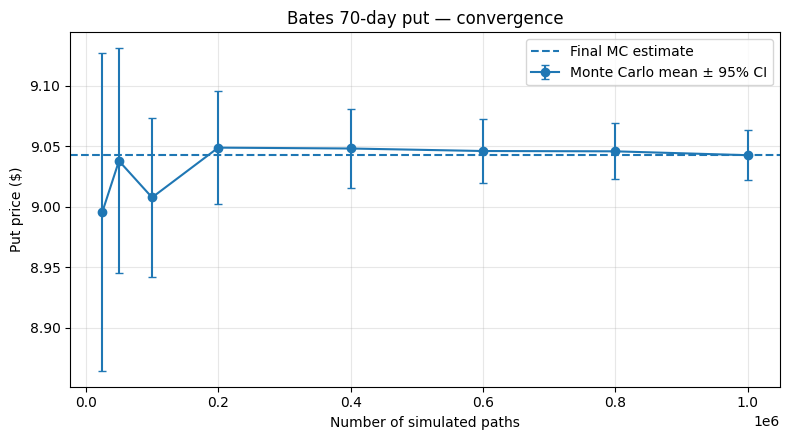

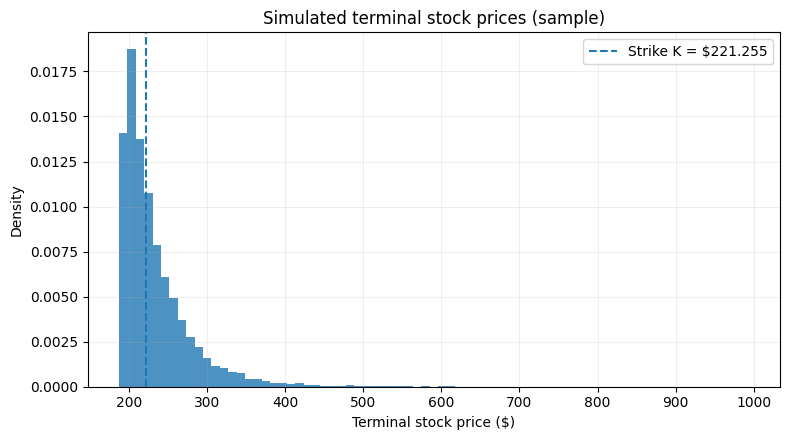

In [135]:
S0, R, Q = 232.90, 0.015, 0.0
TRADING_DAYS, N_STEPS = 250, 280
T = 70 / TRADING_DAYS
K = 0.95 * S0

FEE_RATE = 0.04
OUT = Path('.')
n_paths=1_000_000

B_LEWIS = np.array([3.03972300, 0.20019475, 1.10321038, 0.99990000,
                    0.08396245, 0.0, 0.0, 0.1])
B_CM_ALT = np.array([19.17000007, 0.04586237, 1.32603283, 0.83003100,
                     0.06494551, 0.83937697, 0.23590122, 0.12060082])

print(f'70-day European put | S0=${S0:.2f} | K=${K:.3f} '
          f'| T={T:.2f} years | r={R:.2%}')
primary, terminal = bates_mc(B_LEWIS, n_paths=n_paths)
print('\nPrimary Bates–Lewis calibration (actual simulated paths):')
print(primary.to_string(index=False, float_format=lambda z:f'{z:.6f}'))
price = float(primary.Price.iloc[-1]); se = float(primary.SE.iloc[-1])
fourier = lewis_put(B_LEWIS)
print(f'\nFourier put price: ${fourier:.6f}')
print(f'Monte Carlo: ${price:.6f}; SE=${se:.6f}; '
        f'95% CI=[${price-1.96*se:.6f}, ${price+1.96*se:.6f}]')
print(f'Forward/martingale diagnostic: ${primary.Martingale_Residual.iloc[-1]:+.6f}')
print(f'4% fee (if applied): ${price*FEE_RATE:.6f}; '
        f'fee-inclusive quote: ${price*(1+FEE_RATE):.6f}')
print('\nSensitivity check: Bates Carr–Madan non-zero-jump local solution')
alt, _ = bates_mc(B_CM_ALT, n_paths=n_paths, seed=SEED+1,
                    milestones=[n_paths], save_terminal_sample=0)
print(alt.to_string(index=False, float_format=lambda z:f'{z:.6f}'))
print(f'Alternative Fourier put: ${lewis_put(B_CM_ALT):.6f}')
print(f'Primary MC - Fourier = ${price-fourier:+.6f} ({(price-fourier)/se:+.2f} MC SE); check time-step bias')
primary.to_csv(OUT/'step2c_convergence.csv', index=False)
alt.to_csv(OUT/'step2c_alternative.csv', index=False)
plot_results(primary, terminal)

# Step 3 — Interest-Rate Risk: CIR Calibration and Euribor Simulation

The client's changing maturity requirements introduce a second source of risk: the interest-rate environment used for discounting and financing. This section builds the supplied Euribor term structure, interpolates it weekly, calibrates a CIR (1985) short-rate model, and simulates model-implied future 12-month Euribor-equivalent rates.

## 3.1 Current Euribor Term Structure

The assignment supplies the following Euribor observations:

| Period | Euribor Rate |
|---|---|
| 1 week | 0.648% |
| 1 month | 0.679% |
| 3 months | 1.173% |
| 6 months | 1.809% |
| 12 months | 2.556% |

Euribor is a money-market quote, so the rates are first converted into deposit-equivalent discount factors and then into continuously compounded zero yields before CIR calibration. Because exact fixing and settlement dates are not supplied, we used the assignment's tenor approximations with an ACT/360 accrual convention.

The model maturity axis is expressed in years separately from the money-market accrual fraction.

Table 17. Euribor Term-Structure Construction


,Tenor,Euribor Quote,ACT/360,Discount Factor,Continuous Zero Yield
0,1 week,0.648%,0.019444,0.999874,0.655%
1,1 month,0.679%,0.083333,0.999434,0.679%
2,3 months,1.173%,0.250000,0.997076,1.171%
3,6 months,1.809%,0.500000,0.991036,1.801%
4,12 months,2.556%,1.000000,0.975077,2.524%


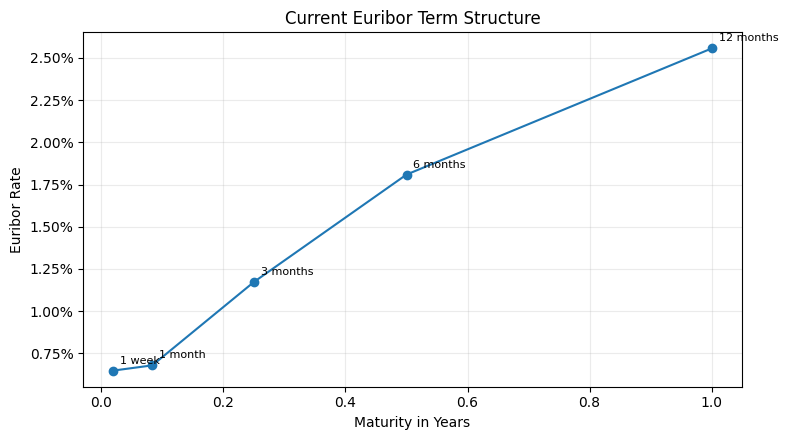

In [136]:
from scipy.interpolate import CubicSpline
from scipy.optimize import minimize

# Assignment Euribor observations
curve_tenors = ["1 week", "1 month", "3 months", "6 months", "12 months"]
euribor_quotes = np.array([0.00648, 0.00679, 0.01173, 0.01809, 0.02556])
approx_days = np.array([7, 30, 90, 180, 360], dtype=float)
accrual_360 = approx_days / 360.0
curve_maturities = np.array([1/52, 1/12, 0.25, 0.50, 1.00], dtype=float)

# Deposit-equivalent discount factors and continuous zero yields
market_discount = 1.0 / (1.0 + euribor_quotes * accrual_360)
market_zero = -np.log(market_discount) / curve_maturities

euribor_curve = pd.DataFrame({
    "Tenor": curve_tenors,
    "Euribor Quote": euribor_quotes,
    "ACT/360": accrual_360,
    "Discount Factor": market_discount,
    "Continuous Zero Yield": market_zero,
})

print("Table 17. Euribor Term-Structure Construction")
display(euribor_curve.style.format({
    "Euribor Quote": "{:.3%}",
    "ACT/360": "{:.6f}",
    "Discount Factor": "{:.6f}",
    "Continuous Zero Yield": "{:.3%}",
}))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(curve_maturities, euribor_quotes, marker="o")
for x, y, name in zip(curve_maturities, euribor_quotes, curve_tenors):
    ax.annotate(name, (x, y), xytext=(5, 5), textcoords="offset points", fontsize=8)
# ax.set_title("Figure 7. Current Euribor Term Structure")

ax.set_title("Current Euribor Term Structure")

ax.set_xlabel("Maturity in Years")
ax.set_ylabel("Euribor Rate")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("step3_euribor_market_curve.png", dpi=180, bbox_inches="tight")
plt.show()

## 3.2 Weekly Cubic-Spline Curve

We use a natural cubic spline to interpolate the continuously compounded zero-yield curve at 52 weekly maturities. This choice is closely aligned with WQU's calibration workflow, which also converts Euribor observations into continuous rates before cubic-spline interpolation. The WQU lesson subsequently derives forward rates from the spline; here, the primary calibration is to the interpolated zero-yield curve to align with the Hull/CIR affine bond formula which simplifies and gives zero-coupon prices and yields directly.

Maximum spline error at original knots: 3.47e-18
Minimum weekly zero yield: 0.655%
Maximum weekly zero yield: 2.524%

Table 18. Representative Weekly Interpolated Euribor Term Structure


,Week,Maturity,Zero Yield,Euribor-Equivalent Simple Rate
0,1,0.0192,0.655%,0.655%
3,4,0.0769,0.672%,0.672%
12,13,0.2500,1.171%,1.173%
25,26,0.5000,1.801%,1.809%
38,39,0.7500,2.204%,2.222%
51,52,1.0000,2.524%,2.556%


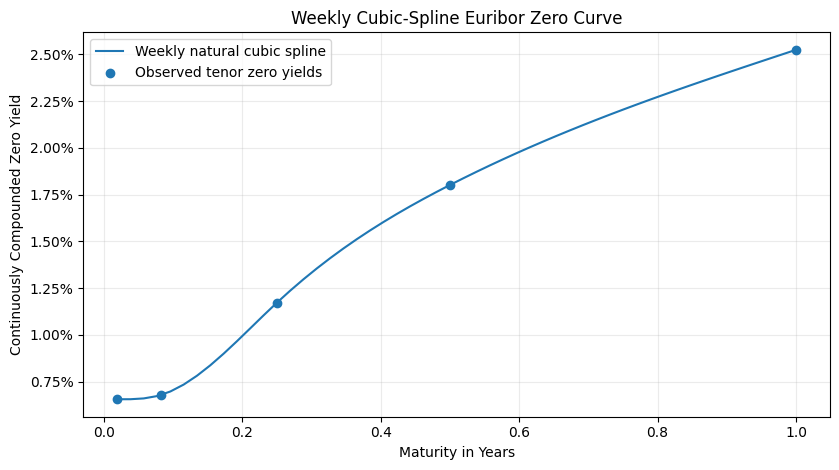

In [137]:
# Natural cubic-spline interpolation of the continuous zero curve
weekly_maturities = np.arange(1, 53) / 52.0
zero_spline = CubicSpline(curve_maturities, market_zero, bc_type="natural")
weekly_zero = zero_spline(weekly_maturities)
weekly_discount = np.exp(-weekly_zero * weekly_maturities)
weekly_simple = (1.0 / weekly_discount - 1.0) / weekly_maturities

weekly_curve = pd.DataFrame({
    "Week": np.arange(1, 53),
    "Maturity": weekly_maturities,
    "Zero Yield": weekly_zero,
    "Euribor-Equivalent Simple Rate": weekly_simple,
})

# Validation at the original spline knots
knot_error = np.max(np.abs(zero_spline(curve_maturities) - market_zero))
print(f"Maximum spline error at original knots: {knot_error:.2e}")
print(f"Minimum weekly zero yield: {weekly_zero.min():.3%}")
print(f"Maximum weekly zero yield: {weekly_zero.max():.3%}")

print("\nTable 18. Representative Weekly Interpolated Euribor Term Structure")
representative_weeks = weekly_curve[weekly_curve["Week"].isin([1, 4, 13, 26, 39, 52])]
display(representative_weeks.style.format({
    "Maturity": "{:.4f}",
    "Zero Yield": "{:.3%}",
    "Euribor-Equivalent Simple Rate": "{:.3%}",
}))

fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.plot(weekly_maturities, weekly_zero, label="Weekly natural cubic spline")
ax.scatter(curve_maturities, market_zero, zorder=3, label="Observed tenor zero yields")
ax.set_title("Weekly Cubic-Spline Euribor Zero Curve")
ax.set_xlabel("Maturity in Years")
ax.set_ylabel("Continuously Compounded Zero Yield")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.savefig("step3_weekly_spline.png", dpi=180, bbox_inches="tight")
plt.show()

## 3.3 CIR Model and Benchmark Equations

Using the Hull/CIR convention, the instantaneous short rate follows

\$$[
dr_t=\kappa(\theta-r_t)dt+\sigma\sqrt{r_t}\,dW_t.
\]$$

Here, \(\kappa\) is the mean-reversion speed, \(\theta\) is the long-run short-rate level, and \(\sigma\) controls the volatility of short-rate shocks. The one-week zero yield is used as the practical proxy for \(r_0\) because no overnight observation is supplied.

The CIR zero-coupon bond price is affine:

\$$[
P(0,T)=A(T)e^{-B(T)r_0},
\]$$

with \$(A(T)\)$ and $\(B(T)\)$ given by the standard Hull/CIR expressions. Classic CIR is an equilibrium model rather than an exact-fit term-structure model, so the objective is to find the parameter set that best approximates the weekly curve rather than force every interpolated point to match exactly.

## 3.4 CIR Calibration

Piggybacking on the WQU calibration lesson which uses the same broad sequence, We first construct the market curve, interpolate it, define the CIR valuation function, minimise MSE, and impose the Feller restriction. We retain that Feller restriction here:

\$$[
2\kappa\theta\geq\sigma^2.
\]$$

The calibration target is the 52-point weekly zero-yield curve. Since those 52 points are generated from only five actual market tenors, they improve numerical resolution but do not represent 52 independent observations.

In [138]:
# CIR affine bond-price and zero-yield functions (Hull / CIR convention)
r0_cir = float(market_zero[0])

def cir_A_B(tau, kappa, theta, sigma):
    tau = np.asarray(tau, dtype=float)
    gamma = np.sqrt(kappa**2 + 2.0 * sigma**2)
    eg = np.exp(gamma * tau)
    denominator = (gamma + kappa) * (eg - 1.0) + 2.0 * gamma
    B = 2.0 * (eg - 1.0) / denominator
    A = (
        2.0 * gamma * np.exp((kappa + gamma) * tau / 2.0) / denominator
    ) ** (2.0 * kappa * theta / sigma**2)
    return A, B

def cir_zero_yield(tau, kappa, theta, sigma, r0=r0_cir):
    A, B = cir_A_B(tau, kappa, theta, sigma)
    price = A * np.exp(-B * r0)
    return -np.log(price) / np.asarray(tau, dtype=float)

def cir_curve_mse(params):
    kappa, theta, sigma = params
    model_zero = cir_zero_yield(weekly_maturities, kappa, theta, sigma)
    return float(np.mean((model_zero - weekly_zero)**2))

# WQU-consistent Feller restriction and positive parameter bounds
bounds_cir = [(0.001, 20.0), (0.0001, 0.50), (0.0001, 2.00)]
feller_constraint = {
    "type": "ineq",
    "fun": lambda x: 2.0*x[0]*x[1] - x[2]**2,
}

# Stage 1: transparent coarse grid
k_grid = [0.10, 0.25, 0.50, 1.00, 2.00, 5.00]
theta_grid = [0.01, 0.03, 0.05, 0.08, 0.12, 0.18]
sigma_grid = [0.02, 0.05, 0.10, 0.20, 0.30, 0.50]
coarse = []
for kappa0 in k_grid:
    for theta0 in theta_grid:
        for sigma0 in sigma_grid:
            if 2*kappa0*theta0 >= sigma0**2:
                coarse.append((cir_curve_mse([kappa0, theta0, sigma0]), [kappa0, theta0, sigma0]))
coarse.sort(key=lambda x: x[0])

# Stage 2: local refinement from the ten best coarse-grid starts
local_solutions = []
for _, start in coarse[:10]:
    opt = minimize(
        cir_curve_mse,
        start,
        method="SLSQP",
        bounds=bounds_cir,
        constraints=[feller_constraint],
        options={"ftol": 1e-15, "maxiter": 5000, "disp": False},
    )
    local_solutions.append(opt)

local_solutions = sorted(local_solutions, key=lambda x: x.fun)
best_cir = local_solutions[0]
kappa_cir, theta_cir, sigma_cir = best_cir.x
cir_fit = cir_zero_yield(weekly_maturities, *best_cir.x)
cir_error = cir_fit - weekly_zero

cir_metrics = {
    "MSE": np.mean(cir_error**2),
    "RMSE": np.sqrt(np.mean(cir_error**2)),
    "RMSE (bps)": np.sqrt(np.mean(cir_error**2))*10000,
    "MAE (bps)": np.mean(np.abs(cir_error))*10000,
    "Max Abs Error (bps)": np.max(np.abs(cir_error))*10000,
}

feller_lhs = 2*kappa_cir*theta_cir
feller_rhs = sigma_cir**2

parameter_table = pd.DataFrame([
    ["Initial short-rate proxy", r"$r_0$", r0_cir, "1-week continuous zero yield"],
    ["Mean-reversion speed", r"$\kappa$", kappa_cir, "Speed of return toward the long-run mean"],
    ["Long-run mean", r"$\theta$", theta_cir, "Long-run short-rate level"],
    ["Rate volatility", r"$\sigma$", sigma_cir, "Scale of short-rate shocks"],
], columns=["Parameter", "Symbol", "Value", "Interpretation"])

print("Table 19. Calibrated CIR Parameters")
display(parameter_table.style.format({"Value":"{:.6f}"}))
print(f"Feller LHS 2*kappa*theta = {feller_lhs:.8f}")
print(f"Feller RHS sigma^2       = {feller_rhs:.8f}")
print("Feller condition:", "HOLDS" if feller_lhs + 1e-10 >= feller_rhs else "DOES NOT HOLD")

print("\nCalibration error statistics")
display(pd.DataFrame([cir_metrics]).style.format({
    "MSE":"{:.10f}", "RMSE":"{:.6f}", "RMSE (bps)":"{:.3f}",
    "MAE (bps)":"{:.3f}", "Max Abs Error (bps)":"{:.3f}"
}))

# Multi-start robustness: show the five best distinct local solutions
robust_rows=[]
for i,opt in enumerate(local_solutions[:5],1):
    k0,t0,s0=opt.x
    robust_rows.append([i,k0,t0,s0,np.sqrt(opt.fun)*10000,2*k0*t0-s0**2])
robust_table=pd.DataFrame(robust_rows,columns=["Rank","kappa","theta","sigma","RMSE (bps)","Feller Slack"])
print("\nTable 20. Multi-Start Calibration Check")
display(robust_table.style.format({
    "kappa":"{:.6f}","theta":"{:.6f}","sigma":"{:.6f}",
    "RMSE (bps)":"{:.3f}","Feller Slack":"{:.6f}"
}))

Table 19. Calibrated CIR Parameters


,Parameter,Symbol,Value,Interpretation
0,Initial short-rate proxy,$r_0$,0.006552,1-week continuous zero yield
1,Mean-reversion speed,$\kappa$,0.723795,Speed of return toward the long-run mean
2,Long-run mean,$\theta$,0.074117,Long-run short-rate level
3,Rate volatility,$\sigma$,0.327554,Scale of short-rate shocks


Feller LHS 2*kappa*theta = 0.10729150
Feller RHS sigma^2       = 0.10729150
Feller condition: HOLDS

Calibration error statistics


,MSE,RMSE,RMSE (bps),MAE (bps),Max Abs Error (bps)
0,0.0000006515,0.000807,8.072,6.191,19.582



Table 20. Multi-Start Calibration Check


,Rank,kappa,theta,sigma,RMSE (bps),Feller Slack
0,1,0.723795,0.074117,0.327554,8.072,0.000000
1,2,0.729977,0.073604,0.315745,8.073,0.007763
2,3,0.740160,0.072703,0.262874,8.079,0.038521
3,4,0.753709,0.071555,0.177213,8.087,0.076459
4,5,0.756015,0.071367,0.160195,8.088,0.082246


**Calibration interpretation.** The calibrated curve fits the weekly spline to single-digit basis-point RMSE, but the multi-start results show that \$(\sigma\)$ is less tightly identified than the overall curve fit. Several parameter combinations produce almost the same term structure. I therefore use the lowest-MSE, Feller-consistent parameter vector as the primary simulation set, while treating the width of the simulated distribution as more model-sensitive than the expected level itself.

Table 21. Selected CIR Fit Points


,Week,Spline Zero Rate,CIR Zero Rate,Error (bps)
0,1,0.655%,0.702%,+4.68
3,4,0.672%,0.840%,+16.76
12,13,1.171%,1.230%,+5.90
25,26,1.801%,1.738%,-6.25
38,39,2.204%,2.187%,-1.66
51,52,2.524%,2.584%,+6.01


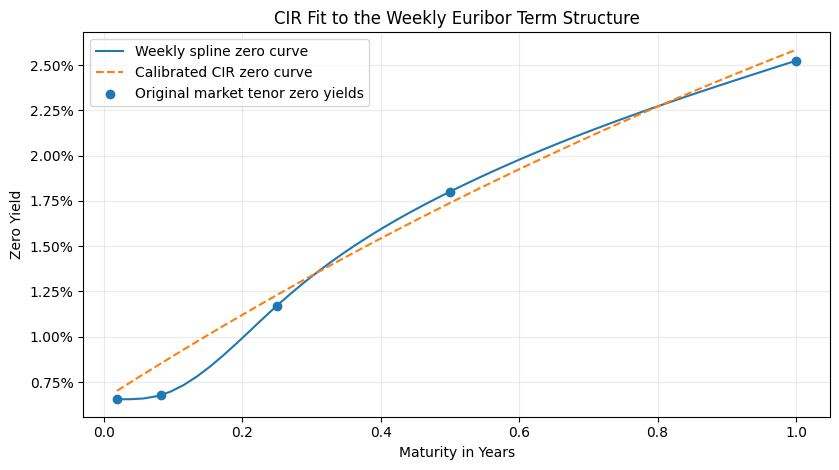

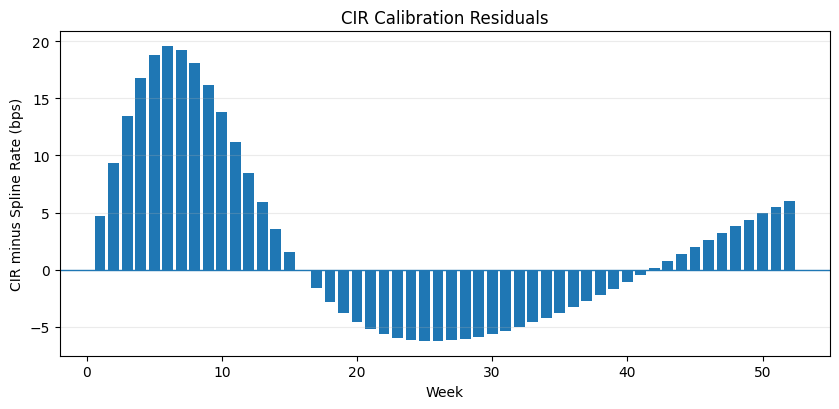

In [139]:
# Calibration fit and residual figures
fit_table = pd.DataFrame({
    "Week": np.arange(1,53),
    "Spline Zero Rate": weekly_zero,
    "CIR Zero Rate": cir_fit,
    "Error (bps)": cir_error*10000,
})
print("Table 21. Selected CIR Fit Points")
display(fit_table[fit_table["Week"].isin([1,4,13,26,39,52])].style.format({
    "Spline Zero Rate":"{:.3%}", "CIR Zero Rate":"{:.3%}", "Error (bps)":"{:+.2f}"
}))

fig, ax = plt.subplots(figsize=(8.5,4.8))
ax.plot(weekly_maturities, weekly_zero, label="Weekly spline zero curve")
ax.plot(weekly_maturities, cir_fit, linestyle="--", label="Calibrated CIR zero curve")
ax.scatter(curve_maturities, market_zero, zorder=3, label="Original market tenor zero yields")
ax.set_title("CIR Fit to the Weekly Euribor Term Structure")
ax.set_xlabel("Maturity in Years")
ax.set_ylabel("Zero Yield")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.grid(alpha=.25); ax.legend()
plt.tight_layout(); plt.savefig("step3_cir_fit.png",dpi=180,bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(8.5,4.2))
ax.bar(np.arange(1,53), cir_error*10000)
ax.axhline(0, linewidth=1)
ax.set_title("CIR Calibration Residuals")
ax.set_xlabel("Week")
ax.set_ylabel("CIR minus Spline Rate (bps)")
ax.grid(axis="y", alpha=.25)
plt.tight_layout(); plt.savefig("step3_cir_residuals.png",dpi=180,bbox_inches="tight"); plt.show()

## 3.6 CIR Monte Carlo Simulation

The CIR state \$(r_t\)$ is an instantaneous short rate, not a 12-month Euribor fixing. We therefore simulate $\(r_t\)$ daily and then convert each simulated state into a one-year zero-coupon bond price and a simple 12-month Euribor-equivalent rate.

The primary simulation uses the exact CIR transition distribution rather than Euler discretisation. This preserves non-negativity and avoids Euler discretisation bias. The requested simulation size is 100,000 paths over 250 daily business-day steps.

Because the parameters were calibrated from today's pricing curve rather than estimated from a historical Euribor time series, the resulting distribution is best interpreted as a risk-neutral/model-implied scenario distribution, not an unbiased real-world forecast.

Table 22. Model-Implied 12-Month Euribor in One Year


,Statistic,Rate
0,Current market 12M Euribor,2.556%
1,Current CIR-implied 12M rate,2.618%
2,Expected 12M rate in 1 year,5.208%
3,Median,4.240%
4,2.5th percentile,2.219%
5,97.5th percentile,13.639%
6,Raw simulation minimum,2.146%
7,Raw simulation maximum,52.007%


Current CIR-implied 12M minus market 12M: +6.17 bps
Analytical E[r_1]: 4.135412%
Simulated  E[r_1]: 4.141048%
Mean-check difference: +0.564 bps
Expected 12M change vs current market: +265.24 bps


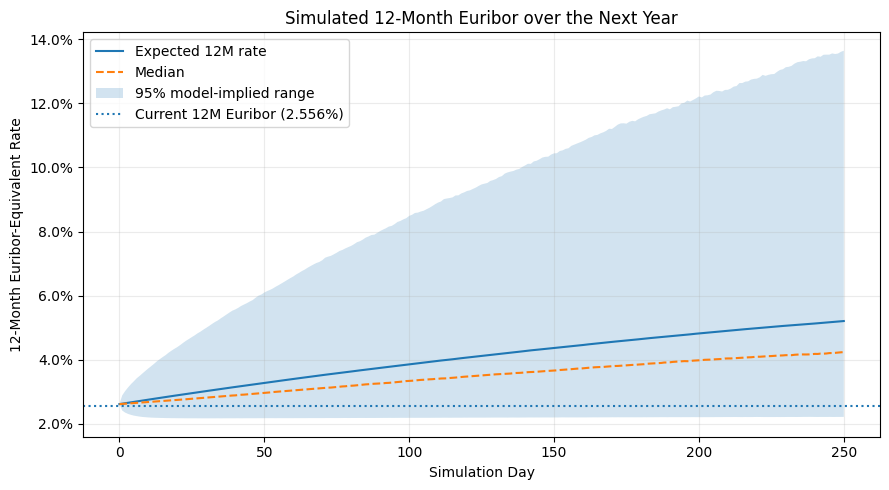

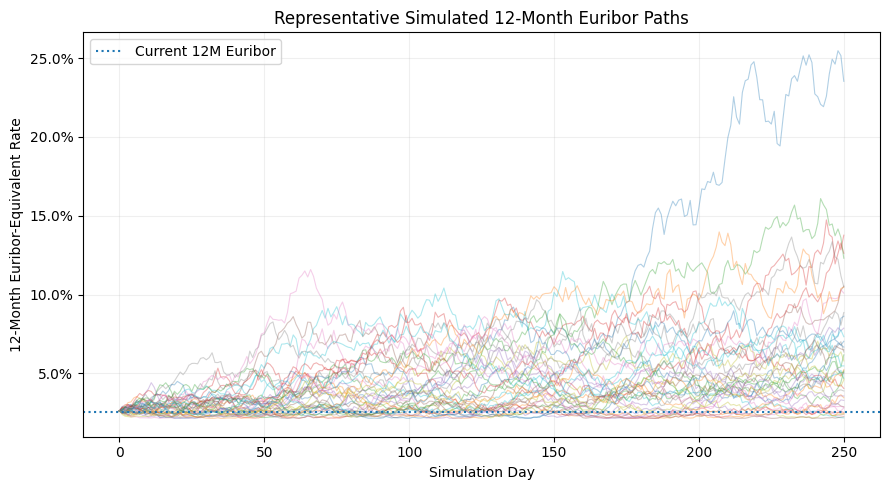

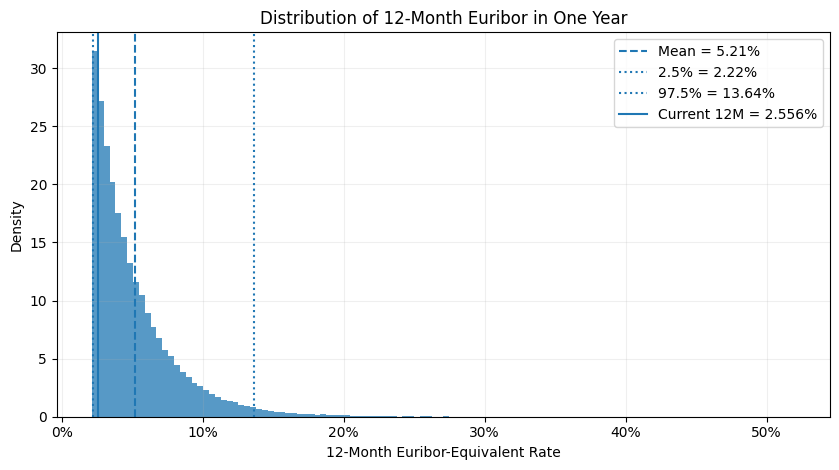

In [140]:
# Exact CIR simulation and future 12-month Euribor-equivalent rates
SEED_CIR = 17149
N_PATHS_CIR = 100_000
N_STEPS_CIR = 250
dt_cir = 1.0 / N_STEPS_CIR
rng_cir = np.random.default_rng(SEED_CIR)

# Exact CIR transition constants
exp_kdt = np.exp(-kappa_cir*dt_cir)
c_cir = sigma_cir**2 * (1-exp_kdt) / (4*kappa_cir)
nu_cir = 4*kappa_cir*theta_cir / sigma_cir**2

# One-year CIR bond coefficients; convert P(t,t+1) to a simple annual rate
A_1y, B_1y = cir_A_B(1.0, kappa_cir, theta_cir, sigma_cir)
def cir_12m_simple_rate(short_rate):
    p_1y = A_1y * np.exp(-B_1y*np.asarray(short_rate))
    return 1.0/p_1y - 1.0

current_model_12m = float(cir_12m_simple_rate(r0_cir))
current_market_12m = 0.02556

short_rate = np.full(N_PATHS_CIR, r0_cir)
rep_paths = np.empty((N_STEPS_CIR+1, 40))
rep_paths[0] = cir_12m_simple_rate(short_rate[:40])

daily_stats=[]
initial_12m = cir_12m_simple_rate(short_rate)
daily_stats.append([0, initial_12m.mean(), np.median(initial_12m),
                    np.quantile(initial_12m,0.025), np.quantile(initial_12m,0.975)])

for day in range(1, N_STEPS_CIR+1):
    noncentrality = (
        4*kappa_cir*exp_kdt*short_rate /
        (sigma_cir**2*(1-exp_kdt))
    )
    short_rate = c_cir * rng_cir.noncentral_chisquare(
        nu_cir, noncentrality, size=N_PATHS_CIR
    )
    rate_12m = cir_12m_simple_rate(short_rate)
    rep_paths[day] = rate_12m[:40]
    daily_stats.append([
        day, rate_12m.mean(), np.median(rate_12m),
        np.quantile(rate_12m,0.025), np.quantile(rate_12m,0.975)
    ])

daily_stats = pd.DataFrame(daily_stats, columns=["Day","Mean","Median","P2.5","P97.5"])
terminal_12m = rate_12m.copy()
terminal_short = short_rate.copy()

# Analytical CIR short-rate mean check
analytic_short_mean_1y = theta_cir + (r0_cir-theta_cir)*np.exp(-kappa_cir)
simulated_short_mean_1y = terminal_short.mean()

terminal_summary = pd.DataFrame([
    ["Current market 12M Euribor", current_market_12m],
    ["Current CIR-implied 12M rate", current_model_12m],
    ["Expected 12M rate in 1 year", terminal_12m.mean()],
    ["Median", np.median(terminal_12m)],
    ["2.5th percentile", np.quantile(terminal_12m,0.025)],
    ["97.5th percentile", np.quantile(terminal_12m,0.975)],
    ["Raw simulation minimum", terminal_12m.min()],
    ["Raw simulation maximum", terminal_12m.max()],
], columns=["Statistic","Rate"])

print("Table 22. Model-Implied 12-Month Euribor in One Year")
display(terminal_summary.style.format({"Rate":"{:.3%}"}))

print(f"Current CIR-implied 12M minus market 12M: {(current_model_12m-current_market_12m)*10000:+.2f} bps")
print(f"Analytical E[r_1]: {analytic_short_mean_1y:.6%}")
print(f"Simulated  E[r_1]: {simulated_short_mean_1y:.6%}")
print(f"Mean-check difference: {(simulated_short_mean_1y-analytic_short_mean_1y)*10000:+.3f} bps")
print(f"Expected 12M change vs current market: {(terminal_12m.mean()-current_market_12m)*10000:+.2f} bps")

# Main daily band figure
fig, ax = plt.subplots(figsize=(9,5))
days = daily_stats["Day"].to_numpy()
ax.plot(days, daily_stats["Mean"], label="Expected 12M rate")
ax.plot(days, daily_stats["Median"], linestyle="--", label="Median")
ax.fill_between(days, daily_stats["P2.5"], daily_stats["P97.5"], alpha=.20, label="95% model-implied range")
ax.axhline(current_market_12m, linestyle=":", label="Current 12M Euribor (2.556%)")
ax.set_title("Simulated 12-Month Euribor over the Next Year")
ax.set_xlabel("Simulation Day")
ax.set_ylabel("12-Month Euribor-Equivalent Rate")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.grid(alpha=.25); ax.legend()
plt.tight_layout(); plt.savefig("step3_cir_simulation_band.png",dpi=180,bbox_inches="tight"); plt.show()

# Representative paths
fig, ax = plt.subplots(figsize=(9,5))
for j in range(rep_paths.shape[1]):
    ax.plot(np.arange(N_STEPS_CIR+1), rep_paths[:,j], alpha=.35, linewidth=.8)
ax.axhline(current_market_12m, linestyle=":", linewidth=1.5, label="Current 12M Euribor")
ax.set_title("Representative Simulated 12-Month Euribor Paths")
ax.set_xlabel("Simulation Day")
ax.set_ylabel("12-Month Euribor-Equivalent Rate")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.grid(alpha=.20); ax.legend()
plt.tight_layout(); plt.savefig("step3_cir_representative_paths.png",dpi=180,bbox_inches="tight"); plt.show()

# Terminal distribution
fig, ax = plt.subplots(figsize=(8.5,4.8))
ax.hist(terminal_12m, bins=120, density=True, alpha=.75)
ax.axvline(terminal_12m.mean(), linestyle="--", label=f"Mean = {terminal_12m.mean():.2%}")
ax.axvline(np.quantile(terminal_12m,.025), linestyle=":", label=f"2.5% = {np.quantile(terminal_12m,.025):.2%}")
ax.axvline(np.quantile(terminal_12m,.975), linestyle=":", label=f"97.5% = {np.quantile(terminal_12m,.975):.2%}")
ax.axvline(current_market_12m, linewidth=1.5, label="Current 12M = 2.556%")
ax.set_title("Distribution of 12-Month Euribor in One Year")
ax.set_xlabel("12-Month Euribor-Equivalent Rate")
ax.set_ylabel("Density")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.grid(alpha=.2); ax.legend()
plt.tight_layout(); plt.savefig("step3_cir_terminal_distribution.png",dpi=180,bbox_inches="tight"); plt.show()

### Calibration uncertainty and the confidence range

The expected rate is relatively stable across the best calibration starts, but the width of the simulated distribution is much more sensitive to the calibrated volatility parameter. This is important because a single current term structure is much better at identifying the curve shape than the unique volatility of future rate paths. The primary 95% range below therefore comes from the best Feller-consistent calibration, but we advice that it should be treated as model-sensitive rather than a guaranteed forecast band.

In [141]:
# Small parameter-identification sensitivity check using near-optimal Feller-consistent solutions
near_opt = []
for opt in local_solutions:
    if np.sqrt(opt.fun)*10000 <= cir_metrics["RMSE (bps)"] + 0.03:
        near_opt.append(opt)
# choose primary, an intermediate-vol solution, and the lowest-vol near-optimal solution if available
candidate_opts = [near_opt[0]]
if len(near_opt) > 2:
    candidate_opts.append(near_opt[len(near_opt)//2])
if len(near_opt) > 1:
    candidate_opts.append(near_opt[-1])

# Remove duplicate sigma choices
unique=[]
for o in candidate_opts:
    if not any(abs(o.x[2]-u.x[2])<1e-6 for u in unique):
        unique.append(o)

sens_rows=[]
for idx,opt in enumerate(unique,1):
    kk,tt,ss=opt.x
    rng_s=np.random.default_rng(SEED_CIR)
    rr=np.full(50_000,r0_cir)
    expk_s=np.exp(-kk*dt_cir)
    c_s=ss**2*(1-expk_s)/(4*kk)
    nu_s=4*kk*tt/ss**2
    A_s,B_s=cir_A_B(1.0,kk,tt,ss)
    for _ in range(N_STEPS_CIR):
        lam_s=4*kk*expk_s*rr/(ss**2*(1-expk_s))
        rr=c_s*rng_s.noncentral_chisquare(nu_s,lam_s,size=len(rr))
    future=(1/(A_s*np.exp(-B_s*rr)))-1
    sens_rows.append([
        "Primary" if idx==1 else f"Near-optimal {idx}",
        kk,tt,ss,np.sqrt(opt.fun)*10000,future.mean(),
        np.quantile(future,.025),np.quantile(future,.975)
    ])

sensitivity_table=pd.DataFrame(sens_rows,columns=[
    "Calibration","kappa","theta","sigma","Curve RMSE (bps)",
    "Expected 12M","2.5%","97.5%"
])
print("Table 23. Calibration-Parameter Sensitivity of the One-Year Rate Distribution")
display(sensitivity_table.style.format({
    "kappa":"{:.4f}","theta":"{:.4f}","sigma":"{:.4f}","Curve RMSE (bps)":"{:.3f}",
    "Expected 12M":"{:.2%}","2.5%":"{:.2%}","97.5%":"{:.2%}"
}))

Table 23. Calibration-Parameter Sensitivity of the One-Year Rate Distribution


,Calibration,kappa,theta,sigma,Curve RMSE (bps),Expected 12M,2.5%,97.5%
0,Primary,0.7238,0.0741,0.3276,8.072,5.19%,2.22%,13.56%
1,Near-optimal 2,0.7621,0.0709,0.0893,8.091,5.11%,3.73%,6.91%
2,Near-optimal 3,0.7665,0.0705,0.0175,8.093,5.10%,4.80%,5.42%


## 3.8 Implications for Product Pricing

Using the primary calibration, the model-implied expected 12-month Euribor-equivalent rate in one year is compared with today's supplied 12-month Euribor of **2.556%**. The previously priced 20-day Asian call and 70-day put will already have expired by that horizon, so paused to ask a relevant question: how would a different interest-rate environment affect comparable new products entered into one year from today.

For a standard non-dividend-paying equity option, a higher risk-free rate generally increases call value and decreases put value, all else equal, because the present value of the strike falls and the risk-neutral forward price rises. A comparable Asian call would normally have positive rate sensitivity as well, although the exact magnitude should be obtained by repricing. A comparable European put would generally be worth less in a higher-rate environment. From our conversations with market practitioners, we understand that any new derivative should be valued using the full term structure prevailing at that time rather than substituting one expected 12-month rate for the whole curve.

Thus, the simulation in the assignment is a pricing/risk scenario, not a statistical forecast and a real-world Euribor forecast would require historical data and an estimate of the market price of interest-rate risk.

In [142]:
expected_12m = terminal_12m.mean()
lower_95 = np.quantile(terminal_12m,0.025)
upper_95 = np.quantile(terminal_12m,0.975)
change_bps = (expected_12m-current_market_12m)*10000

step3_summary = pd.DataFrame([
    ["Current 1W Euribor", 0.00648],
    ["Current 12M Euribor", current_market_12m],
    ["CIR r0 proxy", r0_cir],
    ["CIR kappa", kappa_cir],
    ["CIR theta", theta_cir],
    ["CIR sigma", sigma_cir],
    ["Calibration RMSE (bps)", cir_metrics["RMSE (bps)"]],
    ["Model-implied current 12M", current_model_12m],
    ["Expected 12M in one year", expected_12m],
    ["95% lower bound", lower_95],
    ["95% upper bound", upper_95],
    ["Raw simulation minimum", terminal_12m.min()],
    ["Raw simulation maximum", terminal_12m.max()],
    ["Change vs current 12M (bps)", change_bps],
], columns=["Measure","Result"])

print("Table 24. CIR Interest-Rate Risk Summary")
for label,val in step3_summary.itertuples(index=False):
    if "bps" in label:
        print(f"{label}: {val:.2f}")
    elif label.startswith("CIR kappa") or label.startswith("CIR theta") or label.startswith("CIR sigma"):
        print(f"{label}: {val:.6f}")
    else:
        print(f"{label}: {val:.3%}")

Table 24. CIR Interest-Rate Risk Summary
Current 1W Euribor: 0.648%
Current 12M Euribor: 2.556%
CIR r0 proxy: 0.655%
CIR kappa: 0.723795
CIR theta: 0.074117
CIR sigma: 0.327554
Calibration RMSE (bps): 8.07
Model-implied current 12M: 2.618%
Expected 12M in one year: 5.208%
95% lower bound: 2.219%
95% upper bound: 13.639%
Raw simulation minimum: 2.146%
Raw simulation maximum: 52.007%
Change vs current 12M (bps): 265.24


## 3.9 Answer to Step 3

The supplied Euribor curve is upward sloping, from 0.648% at one week to 2.556% at twelve months. We converted the money-market quotes into deposit-equivalent discount factors and continuously compounded zero yields, then used a natural cubic spline to construct a 52-point weekly curve. The CIR calibration uses the Hull/CIR affine bond-pricing equations and follows WQU's market-calibration workflow.

The primary Feller-consistent calibration gives:

\$$[
r_0=0.6552\%,\qquad
\kappa=0.723841,\qquad
\theta=0.074114,\qquad
\sigma=0.327556.
\]$$

The weekly-curve calibration has an RMSE of 8.07 basis points, with an MAE of 6.19 basis points. The Feller condition holds approximately at the boundary. The multi-start results show that the fitted curve is more stable than the volatility parameter itself, so the width of simulated tail outcomes is more model-sensitive than the expected level.

Using these parameters, I simulated 100,000 daily CIR paths over one year with the exact CIR transition law. The simulated short rate was converted into a model-implied 12-month Euribor-equivalent rate through the CIR one-year zero-coupon bond price. The current model-implied 12-month rate is 2.618%, close to the supplied 2.556% market rate.

At a 95% model-implied scenario level, the one-year-ahead 12-month Euribor-equivalent rate lies between 2.219% and 13.638%. Its expected value is 5.208%, which is approximately 265 basis points above today's 2.556% rate. Across all 100,000 simulations, the raw minimum and maximum are 2.146% and 52.005%, respectively; these are simulation extremes rather than the central 95% risk range.

The expected increase points to a higher-rate pricing environment for comparable new derivatives entered into one year from today. All else equal, higher risk-free rates generally support call values and reduce put values. Actual future pricing should nevertheless use the complete prevailing term structure, and the CIR distribution should be treated as a risk-neutral/model-implied scenario rather than a guaranteed economic forecast.

# Overall Findings

The option data are not perfectly put-call-parity consistent, so part of the calibration error is embedded in the observed quotes rather than caused by the model. This is more pronounced in the 60-day sample than in the 15-day sample.

For the 15-day Heston calibration, Lewis and Carr-Madan produce nearly identical option values when the parameters are held fixed. Independent calibrations can nevertheless produce different long-run parameters with almost unchanged fitted prices, showing that the short-dated price surface is more tightly identified than a unique Heston parameter vector.

At 60 days, the best Bates calibrations under both Fourier approaches collapse toward the zero-jump Heston limit. A materially non-zero-jump solution can still achieve almost the same MSE, so the jump decomposition is weakly identified by this small cross-section.

The client instruments are more stable than the underlying parameter vectors. The 20-day ATM Asian call has a fair value of about $4.67, while the 70-day 95%-moneyness put has a fair value of about $9.03. In both cases, the alternative calibrations move the product value much less than they move individual model parameters.

This is the main practical result: calibration uncertainty matters, but the final short-dated client prices are materially more stable than the raw parameter estimates.


The interest-rate analysis adds a separate source of model risk. The supplied Euribor curve is strongly upward sloping, while classic CIR can only approximate the weekly spline because it is a one-factor equilibrium model. The expected one-year-ahead 12-month rate is more stable across near-optimal calibrations than the width of its simulated distribution, so the central rate level is more robust than the tail range.


# References

Bates, David S. “Jumps and Stochastic Volatility: Exchange Rate Processes Implicit in Deutsche Mark Options.” The Review of Financial Studies, vol. 9, no. 1, 1996, pp. 69–107.

Carr, Peter, and Dilip B. Madan. “Option Valuation Using the Fast Fourier Transform.” Journal of Computational Finance, vol. 2, no. 4, 1999, pp. 61–73.

Cox, John C., Jonathan E. Ingersoll Jr., and Stephen A. Ross. “A Theory of the Term Structure of Interest Rates.” *Econometrica*, vol. 53, no. 2, 1985, pp. 385–407.

CFA Institute. Fixed Income: Term Structure Models. CFA Program Curriculum.

European Money Markets Institute. Benchmark Determination Methodology for Euribor.

Global Association of Risk Professionals. FRM Exam Part I: Valuation and Risk Models.

Heston, Steven L. “A Closed-Form Solution for Options with Stochastic Volatility with Applications to Bond and Currency Options.” *The Review of Financial Studies, vol. 6, no. 2, 1993, pp. 327–343.

Hull, John C. Options, Futures, and Other Derivatives. 11th ed., Pearson, 2022.

Lewis, Alan L. “A Simple Option Formula for General Jump-Diffusion and Other Exponential Lévy Processes.” 2001.

WorldQuant University. MScFE 622 Stochastic Modeling course materials.

WorldQuant University. MScFE 620 Derivative Pricing course materials.

**Note:** *ChatGPT was used to bebugg and restructure the codes, and combine the individual Jupyter notebooks that each group member worked on*.

